---
<h1 style="text-align: center;"><strong>Data Science & Statistical Computing</strong></h1>
<h2 style="text-align: center;"><strong>CheckPoint05</strong></h2>
<h3 style="text-align: center;"><strong>Random Forest, XGBoost e LightGBM: modelagem, tuning, avaliação e deploy</strong></h3>
<h4 style="text-align: center;"><strong>Versão única</strong></h4>

<style>
.jp-MarkdownOutput, .text_cell_render {
    font-family: "Latin Modern Roman", "CMU Serif", Georgia, "DejaVu Serif", serif;
    font-size: 18px;
    line-height: 1.6;
}
.jp-MarkdownOutput p, .text_cell_render p,
.jp-MarkdownOutput li, .text_cell_render li {
    line-height: 1.6;
}
</style>

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Configuração visual:</strong> o notebook prioriza tipografia serifada para células Markdown. A renderização de CSS pode variar entre Jupyter Notebook, JupyterLab, VS Code e Google Colab; quando uma fonte não estiver disponível, o visualizador utilizará uma alternativa local. O código permanece com fonte monoespaçada do ambiente.
</div>

<br>

---

<br>

## **Identificação dos alunos**

A atividade deve ser realizada em **grupos de no máximo 5 alunos**. Preencha, abaixo, o nome e o RM de cada integrante do grupo. Caso o grupo tenha menos de cinco integrantes, mantenha sem preenchimento os campos não utilizados.


In [1]:
#@title Identificação
Nome_1 = "Pedro Henrique Vasco Antonieti" #@param {type:"string"}
RM_1 = "570815" #@param {type:"string"}
Nome_2 = "" #@param {type:"string"}
RM_2 = "" #@param {type:"string"}
Nome_3 = "" #@param {type:"string"}
RM_3 = "" #@param {type:"string"}
Nome_4 = "" #@param {type:"string"}
RM_4 = "" #@param {type:"string"}
Nome_5 = "" #@param {type:"string"}
RM_5 = "" #@param {type:"string"}

<br>

---

<br>

# **CheckPoint05**

## **Objetivos**

- Estruturar um problema real de **classificação** ou **regressão** a partir de uma base de dados escolhida pelo grupo.
- Realizar **data wrangling**, análise exploratória e seleção justificada das variáveis preditoras.
- Implementar e comparar **Random Forest**, **XGBoost** e **LightGBM** sob o mesmo protocolo experimental.
- Ajustar hiperparâmetros com **Grid Search** e **Optuna**, sem utilizar o conjunto de teste durante a busca.
- Selecionar o melhor modelo com base em evidências quantitativas e analisar **overfitting** e **underfitting**.
- Avaliar o modelo final em dados não utilizados no desenvolvimento e construir um teste de consistência das previsões.
- Disponibilizar o projeto em um repositório **GitHub** e uma interface funcional em **Streamlit**.

## **Instruções**

- Leia cada enunciado com atenção.
- Observe a pontuação indicada em cada questão. A atividade vale **10 pontos** no total.
- O grupo deve escolher **um único problema** que possa ser tratado como classificação ou regressão e utilizar a mesma base em toda a atividade.
- A base pode ser pública, institucional autorizada ou coletada pelo grupo. A fonte, a licença ou a forma de obtenção devem ser documentadas.
- O problema deve produzir uma representação tabular de atributos e variável-alvo. Não utilize dados pessoais ou sensíveis sem autorização e justificativa acadêmica adequada.
- Sempre que necessário, registre o raciocínio antes da implementação em Python.
- Quando o item pedir interpretação, responda com base nos resultados obtidos, não apenas com definições genéricas.
- Responda os exercícios nos espaços indicados. Caso seja necessário, adicione células para complementar a resposta.
- Indique de forma organizada a solução dos exercícios.
- Preocupe-se em fazer um código Python limpo, documentado e reprodutível. Esse aspecto será avaliado ao longo de toda a atividade.
- O conjunto de **teste deve permanecer isolado** durante seleção de variáveis, comparação de modelos e tuning. Ele só poderá ser utilizado no Exercício 7.
- O envio da atividade deve incluir o notebook `.ipynb`, o link do repositório GitHub e o link da aplicação Streamlit.
- Cada grupo deverá realizar uma **apresentação oral da solução, com duração máxima de 10 minutos**, sintetizando o problema, as principais decisões metodológicas, a comparação entre os modelos, o modelo final e a demonstração da aplicação.
- Execute o notebook do início ao fim antes do envio. Ele não deve conter erros durante a execução.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Entregáveis obrigatórios:</strong> notebook final, repositório GitHub reproduzível, aplicação Streamlit funcional e **apresentação oral da solução com duração máxima de 10 minutos**. O repositório deve conter, no mínimo, README com instruções de execução, arquivo de dependências, código da aplicação e os arquivos necessários para reproduzir o treinamento ou carregar o modelo final.
</div>

In [2]:
# imports e configuração visual do notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib import font_manager

fontes_preferidas = [
    "Latin Modern Roman",
    "CMU Serif",
    "Georgia",
    "DejaVu Serif",
]

fonte_serif = "DejaVu Serif"
for fonte in fontes_preferidas:
    try:
        font_manager.findfont(fonte, fallback_to_default=False)
        fonte_serif = fonte
        break
    except Exception:
        pass

sns.set_theme(style="whitegrid", palette="viridis")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [fonte_serif, "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "text.usetex": False,
    "figure.figsize": (9, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

print(f"Fonte serifada selecionada para os gráficos: {fonte_serif}")

Fonte serifada selecionada para os gráficos: Georgia


<br>

---

<br>

## **Notação utilizada na atividade**

Considere a base de dados como

$$
\mathcal{D}=\{(\mathbf{x}_i,y_i)\}_{i=1}^{n},
$$

em que $\mathbf{x}_i$ representa as variáveis preditoras da observação $i$ e $y_i$ representa a variável-alvo. Ao organizar os dados, utilize a notação

$$
\mathbf{X} \quad \text{para a matriz de atributos},
\qquad
\mathbf{y} \quad \text{para o vetor da variável-alvo}.
$$

A separação deve produzir

$$
\mathcal{D}_{\mathrm{treino}}
\quad \text{e} \quad
\mathcal{D}_{\mathrm{teste}},
$$

sendo $\mathcal{D}_{\mathrm{teste}}$ mantido fora de todo o processo de seleção e tuning. Os três modelos serão indicados por

$$
M_{\mathrm{RF}},
\qquad
M_{\mathrm{XGB}},
\qquad
M_{\mathrm{LGBM}}.
$$

As previsões serão representadas por $\hat{\mathbf{y}}$. Para hiperparâmetros, utilize $\boldsymbol{\theta}$ e registre os melhores valores encontrados por cada estratégia de busca.

<br>

---

<br>

## **Exercícios propostos**

A atividade foi organizada como um fluxo completo de desenvolvimento de um projeto de machine learning. Os sete exercícios devem ser respondidos em sequência, pois as decisões tomadas nas etapas iniciais serão utilizadas nas etapas seguintes.

<br>

---

<br>

### **Exercício 1 — Definição do problema e da base de dados — 1,0 ponto**

Escolha um problema real que possa ser tratado por **Random Forest**, **XGBoost** e **LightGBM**. O problema pode ser de classificação ou regressão.

1. **Contexto e problema — 0,25 ponto.** Descreva o contexto, a pergunta que será respondida e por que uma solução preditiva é adequada.
2. **Variável-alvo — 0,25 ponto.** Defina $y$, informe se o problema é de classificação ou regressão e explique o significado da previsão $\hat{y}$ no domínio escolhido.
3. **Base de dados — 0,25 ponto.** Informe a fonte, o método de obtenção, o número inicial de linhas e colunas, a unidade observacional e as principais variáveis disponíveis.
4. **Critério de sucesso — 0,25 ponto.** Defina a métrica principal que será usada para comparar os modelos e justifique a escolha. Métricas auxiliares podem ser utilizadas, mas deve existir uma métrica principal comum aos três algoritmos.

**Sugestões de apoio visual:** tabela com dicionário de dados, gráfico da distribuição da variável-alvo e, quando aplicável, gráfico da frequência das classes.

**Resposta do aluno — Exercício 1**


**1. Contexto e problema.** Uma operadora de telefonia e internet perde receita toda vez que um cliente cancela o serviço (*churn*), e conquistar um cliente novo custa mais do que manter um que já está na base. A pergunta deste trabalho é: **com o perfil, os serviços contratados e os dados da conta de um cliente, é possível prever se ele vai cancelar?** Uma solução supervisionada é adequada porque a base traz, para cada cliente, o desfecho já observado (cancelou ou não), então dá para aprender a relação entre as características e o desfecho e aplicá-la a clientes ativos. A previsão serve para priorizar ações de retenção (contato, desconto, mudança de plano) nos clientes de maior risco.

**2. Variável-alvo.** $y$ é a coluna `Churn`: vale 1 se o cliente cancelou o serviço no último mês e 0 caso contrário. É um problema de **classificação binária**. O modelo devolve uma probabilidade estimada de cancelamento, $\hat{p}=P(y=1\mid\mathbf{x})$, e a previsão $\hat{y}$ é 1 ("vai cancelar") quando $\hat{p}\ge 0{,}5$. No domínio, $\hat{y}=1$ significa "cliente em risco, vale acionar a retenção".

**3. Base de dados.** *Telco Customer Churn*, base de exemplo publicada pela IBM, obtida por download direto do repositório público [IBM/telco-customer-churn-on-icp4d](https://github.com/IBM/telco-customer-churn-on-icp4d) (licença Apache-2.0); a mesma base está no Kaggle como `blastchar/telco-customer-churn`. O arquivo está versionado em `data/Telco-Customer-Churn.csv`. São **7.043 linhas e 21 colunas**, e a unidade observacional é o **cliente** (uma linha por `customerID`). As variáveis se dividem em perfil (gênero, idoso, cônjuge, dependentes), serviços contratados (telefone, internet e seis adicionais), conta (tempo como cliente, contrato, forma de pagamento, valores cobrados) e o alvo. A base não tem dado pessoal identificável: o identificador é um código sem relação com pessoas reais.

Uma limitação que assumo desde já: segundo a própria IBM, os dados descrevem uma operadora **fictícia** da Califórnia. O problema de negócio é real e comum no setor, mas os registros foram criados para demonstração, então os resultados valem como exercício metodológico, não como retrato de um mercado.

**4. Critério de sucesso.** A métrica principal é a **ROC-AUC**, calculada sobre $\hat{p}$. Dois motivos: (i) o uso prático do modelo é ordenar clientes por risco para decidir quem contatar primeiro, e a AUC mede exatamente a qualidade dessa ordenação (a probabilidade de um cliente que cancelou receber score maior que um que não cancelou); (ii) ela não depende de um limiar de decisão nem é inflada pela classe majoritária, o que importa porque só 26,5% dos clientes cancelaram (gráfico abaixo). A acurácia sozinha enganaria: prever "ninguém cancela" já acerta 73,5%. Como métricas auxiliares uso recall, precisão, F1 e acurácia no limiar 0,5 (detalhadas no Exercício 3).

In [3]:
# Resposta do aluno - exercício 1
# carga da base e resumo inicial
SEED = 42
CAMINHO_DADOS = "data/Telco-Customer-Churn.csv"

df_bruto = pd.read_csv(CAMINHO_DADOS)
print(f"Dimensões iniciais: {df_bruto.shape[0]} linhas x {df_bruto.shape[1]} colunas")
print(f"Unidade observacional: cliente ({df_bruto['customerID'].nunique()} customerID distintos)")
df_bruto.head()

Dimensões iniciais: 7043 linhas x 21 colunas
Unidade observacional: cliente (7043 customerID distintos)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# dicionário de dados: nome original, nome adotado em português e significado
dicionario = pd.DataFrame(
    [
        ("customerID", "id_cliente", "identificador do cliente"),
        ("gender", "genero", "gênero do cliente"),
        ("SeniorCitizen", "idoso", "1 se o cliente tem 65 anos ou mais, 0 caso contrário"),
        ("Partner", "tem_conjuge", "possui cônjuge"),
        ("Dependents", "tem_dependentes", "possui dependentes"),
        ("tenure", "meses_como_cliente", "tempo de permanência na operadora, em meses"),
        ("PhoneService", "telefone", "possui serviço de telefone"),
        ("MultipleLines", "multiplas_linhas", "possui mais de uma linha telefônica"),
        ("InternetService", "internet", "tipo de internet contratada (DSL, fibra óptica ou nenhuma)"),
        ("OnlineSecurity", "seguranca_online", "adicional de segurança online"),
        ("OnlineBackup", "backup_online", "adicional de backup online"),
        ("DeviceProtection", "protecao_dispositivo", "adicional de proteção do dispositivo"),
        ("TechSupport", "suporte_tecnico", "adicional de suporte técnico"),
        ("StreamingTV", "streaming_tv", "adicional de streaming de TV"),
        ("StreamingMovies", "streaming_filmes", "adicional de streaming de filmes"),
        ("Contract", "contrato", "tipo de contrato (mensal, anual ou bienal)"),
        ("PaperlessBilling", "fatura_digital", "recebe a fatura apenas em formato digital"),
        ("PaymentMethod", "forma_pagamento", "forma de pagamento da fatura"),
        ("MonthlyCharges", "valor_mensal", "valor cobrado por mês (US$)"),
        ("TotalCharges", "valor_total", "valor total já cobrado do cliente (US$)"),
        ("Churn", "cancelou", "variável-alvo: o cliente cancelou o serviço no último mês"),
    ],
    columns=["coluna original", "nome adotado", "descrição"],
).set_index("coluna original")

dicionario["tipo lido"] = df_bruto.dtypes.astype(str)
dicionario["valores distintos"] = df_bruto.nunique()
dicionario

,nome adotado,descrição,tipo lido,valores distintos
coluna original,,,,
customerID,id_cliente,identificador do cliente,str,7043
gender,genero,gênero do cliente,str,2
SeniorCitizen,idoso,"1 se o cliente tem 65 anos ou mais, 0 caso con...",int64,2
Partner,tem_conjuge,possui cônjuge,str,2
Dependents,tem_dependentes,possui dependentes,str,2
tenure,meses_como_cliente,"tempo de permanência na operadora, em meses",int64,73
PhoneService,telefone,possui serviço de telefone,str,2
MultipleLines,multiplas_linhas,possui mais de uma linha telefônica,str,3
InternetService,internet,"tipo de internet contratada (DSL, fibra óptica...",str,3


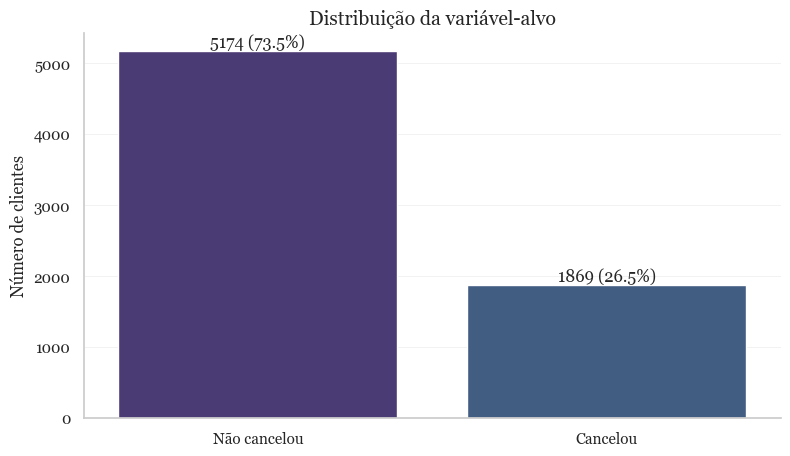

In [5]:
# distribuição da variável-alvo
contagem = df_bruto["Churn"].map({"No": "Não cancelou", "Yes": "Cancelou"}).value_counts()

ax = sns.barplot(x=contagem.index, y=contagem.values, hue=contagem.index, legend=False)
for i, v in enumerate(contagem.values):
    ax.text(i, v, f"{v} ({v / len(df_bruto):.1%})", ha="center", va="bottom")
ax.set(title="Distribuição da variável-alvo", xlabel="", ylabel="Número de clientes")
plt.show()

A base tem 5.174 clientes que ficaram (73,5%) e 1.869 que cancelaram (26,5%). O desbalanceamento é moderado: não exige reamostragem, mas pede estratificação na separação dos dados e uma métrica que não se deixe levar pela classe majoritária. No dicionário já aparece um problema de qualidade: `TotalCharges` foi lida como texto, apesar de ser um valor em dólares. Isso é tratado no Exercício 2.

<br>

---

<br>

### **Exercício 2 — Data wrangling e análise exploratória — 1,5 ponto**

Prepare a base para a etapa de modelagem. Toda transformação deve ser justificada e documentada.

1. **Diagnóstico de qualidade — 0,30 ponto.** Verifique tipos de dados, valores ausentes, duplicidades, categorias inconsistentes, valores impossíveis e outras anomalias relevantes.
2. **Tratamento dos dados — 0,40 ponto.** Execute o data wrangling necessário. Explique o que foi alterado, removido, imputado, convertido ou recodificado e por quê. Não remova observações ou variáveis apenas para melhorar métricas.
3. **Análise exploratória — 0,50 ponto.** Produza gráficos coerentes com o problema e interprete o que eles mostram sobre $\mathbf{X}$ e $\mathbf{y}$. A análise deve conter pelo menos três visualizações úteis ao desenvolvimento do modelo.
4. **Base final — 0,30 ponto.** Apresente as dimensões da base após o tratamento, verifique novamente ausências e duplicidades e registre quais decisões de preparação ainda precisarão ocorrer dentro do pipeline de modelagem.

**Sugestões de gráficos:** distribuição da variável-alvo; barras de valores ausentes; boxplots ou histogramas para variáveis numéricas; contagens para variáveis categóricas; matriz de correlação quando fizer sentido; relação entre variáveis importantes e o alvo.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Atenção:</strong> qualquer transformação que aprenda parâmetros dos dados, como imputação baseada em estatísticas da amostra ou codificação aprendida, deve ser ajustada sem acesso ao conjunto de teste. Quando aplicável, faça essas etapas dentro de um pipeline.
</div>

**Resposta do aluno — Exercício 2**


O diagnóstico é feito sobre a base bruta, com os nomes originais em inglês. No tratamento, colunas e categorias passam para português (mapeamento no dicionário de dados do Exercício 1), para que gráficos, tabelas e a aplicação fiquem legíveis.

In [6]:
# Resposta do aluno - exercício 2
# 2.1 diagnóstico: tipos, ausências e duplicidades
diagnostico = pd.DataFrame({
    "tipo": df_bruto.dtypes.astype(str),
    "ausentes (NaN)": df_bruto.isna().sum(),
    "valores distintos": df_bruto.nunique(),
})
display(diagnostico)

print("Linhas duplicadas (linha inteira):", df_bruto.duplicated().sum())
print("customerID repetidos:", df_bruto["customerID"].duplicated().sum())
print("Linhas idênticas ignorando o customerID:", df_bruto.drop(columns="customerID").duplicated().sum())

,tipo,ausentes (NaN),valores distintos
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


Linhas duplicadas (linha inteira): 0
customerID repetidos: 0


Linhas idênticas ignorando o customerID: 22


In [7]:
# 2.1 diagnóstico: TotalCharges foi lido como texto; quais valores não são numéricos?
total_numerico = pd.to_numeric(df_bruto["TotalCharges"], errors="coerce")
nao_numericos = df_bruto[total_numerico.isna()]

print(f"TotalCharges não numérico em {len(nao_numericos)} linhas. Valores encontrados: {nao_numericos['TotalCharges'].unique().tolist()}")
nao_numericos[["customerID", "tenure", "Contract", "MonthlyCharges", "TotalCharges", "Churn"]]

TotalCharges não numérico em 11 linhas. Valores encontrados: [' ']


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,Two year,52.55,,No
753,3115-CZMZD,0,Two year,20.25,,No
936,5709-LVOEQ,0,Two year,80.85,,No
1082,4367-NUYAO,0,Two year,25.75,,No
1340,1371-DWPAZ,0,Two year,56.05,,No
3331,7644-OMVMY,0,Two year,19.85,,No
3826,3213-VVOLG,0,Two year,25.35,,No
4380,2520-SGTTA,0,Two year,20.00,,No
5218,2923-ARZLG,0,One year,19.70,,No
6670,4075-WKNIU,0,Two year,73.35,,No


In [8]:
# 2.1 diagnóstico: categorias de cada variável qualitativa
for coluna in df_bruto.drop(columns=["customerID", "TotalCharges"]).select_dtypes(exclude="number"):
    print(f"{coluna}: {sorted(df_bruto[coluna].unique())}")

gender: ['Female', 'Male']
Partner: ['No', 'Yes']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No', 'No phone service', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'No internet service', 'Yes']
OnlineBackup: ['No', 'No internet service', 'Yes']
DeviceProtection: ['No', 'No internet service', 'Yes']
TechSupport: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
StreamingMovies: ['No', 'No internet service', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['No', 'Yes']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn: ['No', 'Yes']


In [9]:
# 2.1 diagnóstico: valores impossíveis e coerência entre colunas
display(df_bruto[["SeniorCitizen", "tenure", "MonthlyCharges"]].assign(TotalCharges=total_numerico).describe().T)

adicionais_internet = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
sem_internet = df_bruto["InternetService"] == "No"
sem_telefone = df_bruto["PhoneService"] == "No"

print("Clientes com tenure = 0:", (df_bruto["tenure"] == 0).sum())
print("'No internet service' aparece exatamente nos clientes sem internet:",
      all(((df_bruto[c] == "No internet service") == sem_internet).all() for c in adicionais_internet))
print("'No phone service' aparece exatamente nos clientes sem telefone:",
      ((df_bruto["MultipleLines"] == "No phone service") == sem_telefone).all())

# o total cobrado deve ser próximo de meses x valor mensal
razao = (total_numerico / (df_bruto["tenure"] * df_bruto["MonthlyCharges"])).dropna()
print(f"TotalCharges / (tenure x MonthlyCharges): mediana {razao.median():.3f}, "
      f"percentis 1% e 99%: {razao.quantile(0.01):.3f} e {razao.quantile(0.99):.3f}")

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


Clientes com tenure = 0: 11
'No internet service' aparece exatamente nos clientes sem internet: True
'No phone service' aparece exatamente nos clientes sem telefone: True
TotalCharges / (tenure x MonthlyCharges): mediana 1.000, percentis 1% e 99%: 0.855 e 1.159


**Diagnóstico (2.1).**

- **Tipos.** `TotalCharges` é numérica mas foi lida como texto. O motivo são **11 linhas com um espaço em branco** no lugar do valor. Todas têm `tenure = 0`: são clientes recém-contratados que ainda não receberam nenhuma fatura (e nenhum deles cancelou). Ou seja, é um ausente "disfarçado", que `isna()` não enxerga.
- **Ausências.** Nenhum `NaN` declarado; o único caso real é o descrito acima.
- **Duplicidades.** Não há linha repetida nem `customerID` repetido. Ignorando o identificador, 22 linhas coincidem com outra em todas as colunas. Todas são de clientes com 1 mês de casa e contrato mensal, a maioria no plano mais básico, sem internet: clientes diferentes com o mesmo perfil, não registros duplicados.
- **Categorias inconsistentes.** Não há erro de grafia, mas há redundância: `No internet service` aparece em seis colunas exatamente nos clientes com `InternetService = No`, e `No phone service` em `MultipleLines` exatamente nos clientes sem telefone (as duas verificações deram `True`). Essas categorias repetem uma informação que já está em outra coluna. Outra inconsistência de formato: `SeniorCitizen` é 0/1 enquanto as demais binárias são `Yes`/`No`.
- **Valores impossíveis.** Não encontrei: `tenure` vai de 0 a 72 meses, `MonthlyCharges` de 18,25 a 118,75 e não há valor negativo. Como checagem de coerência, `TotalCharges` deveria ficar perto de `tenure × MonthlyCharges`: a razão tem mediana 1,000 e fica entre 0,855 e 1,159 em 98% dos clientes, diferença compatível com reajustes de preço ao longo do contrato.

In [10]:
# 2.2 tratamento dos dados
df = df_bruto.copy()

# (a) TotalCharges: texto -> número; os vazios são clientes com 0 meses, que ainda não foram cobrados
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

# (b) alvo binário: 1 = cancelou, 0 = não cancelou
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# (c) categorias redundantes e tradução das categorias para português
df = df.replace({
    "No internet service": "Não", "No phone service": "Não",
    "Yes": "Sim", "No": "Não",
    "Female": "Feminino", "Male": "Masculino",
    "Fiber optic": "Fibra óptica",
    "Month-to-month": "Mensal", "One year": "Anual", "Two year": "Bienal",
    "Electronic check": "Cheque eletrônico", "Mailed check": "Cheque pelo correio",
    "Bank transfer (automatic)": "Transferência bancária (automática)",
    "Credit card (automatic)": "Cartão de crédito (automático)",
})

# (d) nomes das colunas em português (mapeamento do dicionário de dados)
df = df.rename(columns=dicionario["nome adotado"].to_dict())

df.head()

,id_cliente,genero,idoso,tem_conjuge,tem_dependentes,meses_como_cliente,telefone,multiplas_linhas,internet,seguranca_online,...,protecao_dispositivo,suporte_tecnico,streaming_tv,streaming_filmes,contrato,fatura_digital,forma_pagamento,valor_mensal,valor_total,cancelou
0,7590-VHVEG,Feminino,0,Sim,Não,1,Não,Não,DSL,Não,...,Não,Não,Não,Não,Mensal,Sim,Cheque eletrônico,29.85,29.85,0
1,5575-GNVDE,Masculino,0,Não,Não,34,Sim,Não,DSL,Sim,...,Sim,Não,Não,Não,Anual,Não,Cheque pelo correio,56.95,1889.50,0
2,3668-QPYBK,Masculino,0,Não,Não,2,Sim,Não,DSL,Sim,...,Não,Não,Não,Não,Mensal,Sim,Cheque pelo correio,53.85,108.15,1
3,7795-CFOCW,Masculino,0,Não,Não,45,Não,Não,DSL,Sim,...,Sim,Sim,Não,Não,Anual,Não,Transferência bancária (automática),42.30,1840.75,0
4,9237-HQITU,Feminino,0,Não,Não,2,Sim,Não,Fibra óptica,Não,...,Não,Não,Não,Não,Mensal,Sim,Cheque eletrônico,70.70,151.65,1


**Tratamento (2.2).** O que mudou e por quê:

| Decisão | Justificativa |
|---|---|
| `TotalCharges` convertida para número; os 11 vazios viraram 0 | O vazio ocorre só com 0 meses de contrato, quando nada foi cobrado ainda. O valor 0 é o correto pelo significado da variável, não uma estimativa. Por ser uma regra de negócio, e não uma estatística calculada da amostra, pode ser aplicada antes da separação treino–teste sem vazamento. |
| `No internet service` e `No phone service` recodificadas para "Não" | Redundantes com `internet` e `telefone`. Manter criaria sete colunas one-hot idênticas entre si. Nenhuma informação se perde. |
| `Churn` convertida para 0/1 (`cancelou`) | Formato exigido pelos estimadores e pelas métricas. |
| Categorias e nomes de colunas traduzidos | Apenas legibilidade; não altera o conteúdo. |
| `SeniorCitizen` mantida como 0/1 (`idoso`) | Já é binária numérica; os modelos de árvore usam direto. |
| Nenhuma linha removida, inclusive as 22 "repetidas" e os 11 clientes novos | São clientes legítimos. Remover os clientes com 0 meses tiraria do modelo justamente o perfil de recém-chegado, e remover linhas para "limpar" a métrica não se justifica. |

Nenhuma dessas etapas aprende parâmetro a partir dos dados; por isso foram feitas na base inteira.

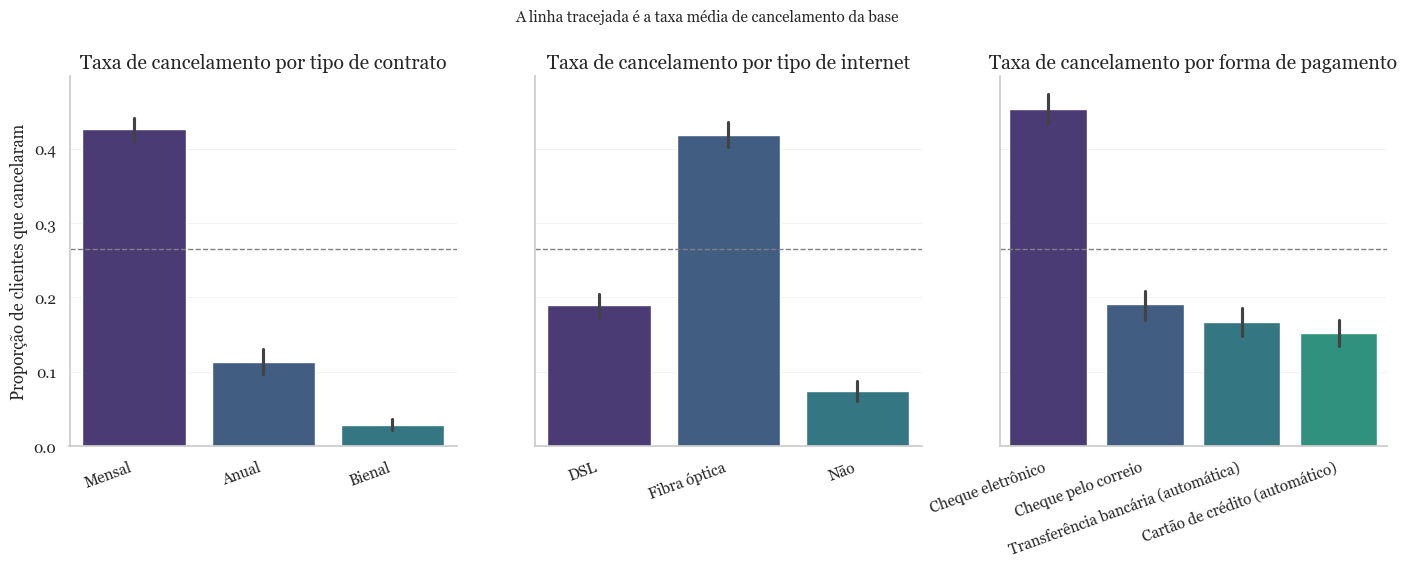

,clientes,taxa_cancelamento
contrato,,
Anual,1473,0.113
Bienal,1695,0.028
Mensal,3875,0.427


,clientes,taxa_cancelamento
internet,,
DSL,2421,0.190
Fibra óptica,3096,0.419
Não,1526,0.074


,clientes,taxa_cancelamento
forma_pagamento,,
Cartão de crédito (automático),1522,0.152
Cheque eletrônico,2365,0.453
Cheque pelo correio,1612,0.191
Transferência bancária (automática),1544,0.167


In [11]:
# 2.3 análise exploratória (1): taxa de cancelamento por contrato, internet e forma de pagamento
ROTULOS = {
    "contrato": "tipo de contrato", "internet": "tipo de internet", "forma_pagamento": "forma de pagamento",
    "meses_como_cliente": "meses como cliente", "valor_mensal": "valor mensal (US$)", "valor_total": "valor total (US$)",
    "idoso": "idoso", "cancelou": "cancelou",
    "seguranca_online": "segurança online", "backup_online": "backup online", "protecao_dispositivo": "proteção do dispositivo",
    "suporte_tecnico": "suporte técnico", "streaming_tv": "streaming de TV", "streaming_filmes": "streaming de filmes",
}

fig, eixos = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, coluna in zip(eixos, ["contrato", "internet", "forma_pagamento"]):
    sns.barplot(data=df, x=coluna, y="cancelou", hue=coluna, legend=False, ax=ax)
    ax.axhline(df["cancelou"].mean(), color="gray", linestyle="--", linewidth=1)
    ax.set(title=f"Taxa de cancelamento por {ROTULOS[coluna]}", xlabel="", ylabel="Proporção de clientes que cancelaram")
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.suptitle("A linha tracejada é a taxa média de cancelamento da base", y=1.02, fontsize=11)
plt.show()

for coluna in ["contrato", "internet", "forma_pagamento"]:
    display(df.groupby(coluna)["cancelou"].agg(clientes="size", taxa_cancelamento="mean").round(3))

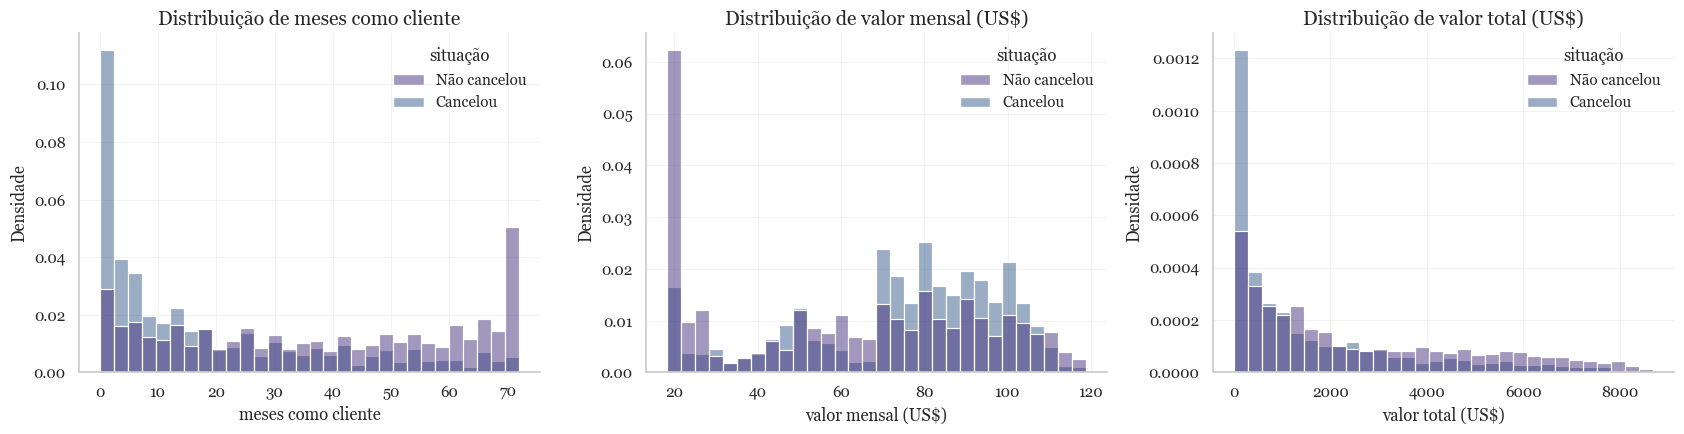

Medianas por situação do cliente:


,meses_como_cliente,valor_mensal,valor_total
situação,,,
Cancelou,10.0,79.650,703.550
Não cancelou,38.0,64.425,1679.525


In [12]:
# 2.3 análise exploratória (2): variáveis numéricas por situação do cliente
situacao = df["cancelou"].map({0: "Não cancelou", 1: "Cancelou"}).rename("situação")
numericas = ["meses_como_cliente", "valor_mensal", "valor_total"]

fig, eixos = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, coluna in zip(eixos, numericas):
    sns.histplot(data=df, x=coluna, hue=situacao, stat="density", common_norm=False, bins=30, ax=ax)
    ax.set(title=f"Distribuição de {ROTULOS[coluna]}", xlabel=ROTULOS[coluna], ylabel="Densidade")
plt.tight_layout()
plt.show()

print("Medianas por situação do cliente:")
df.groupby(situacao)[numericas].median()

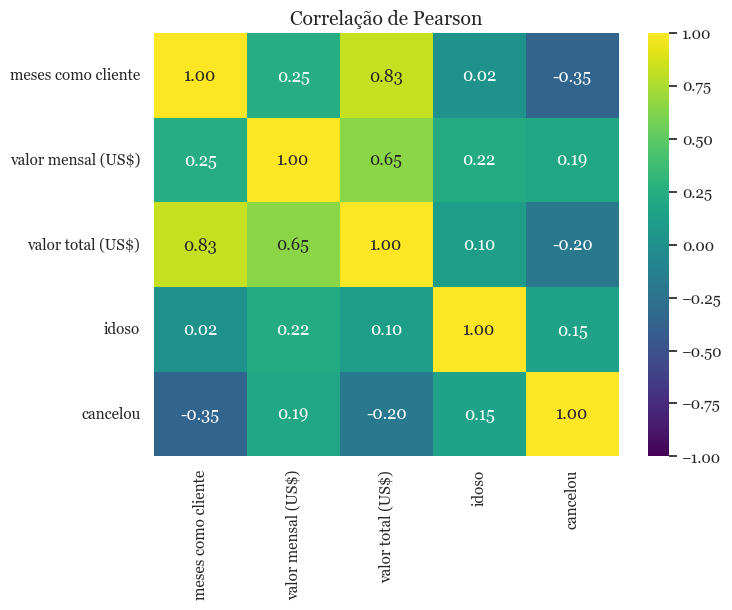

In [13]:
# 2.3 análise exploratória (3): correlação entre as variáveis numéricas e o alvo
colunas_corr = ["meses_como_cliente", "valor_mensal", "valor_total", "idoso", "cancelou"]
correlacao = df[colunas_corr].corr().rename(index=ROTULOS, columns=ROTULOS)

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="viridis", vmin=-1, vmax=1)
plt.title("Correlação de Pearson")
plt.show()

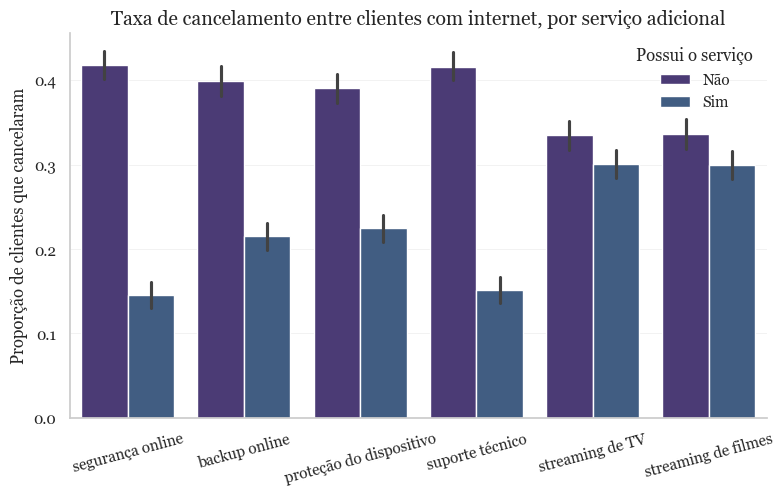

In [14]:
# 2.3 análise exploratória (4): taxa de cancelamento com e sem cada serviço adicional
adicionais = ["seguranca_online", "backup_online", "protecao_dispositivo", "suporte_tecnico", "streaming_tv", "streaming_filmes"]
com_internet = df[df["internet"] != "Não"]
taxas = com_internet.melt(id_vars="cancelou", value_vars=adicionais, var_name="serviço", value_name="possui")
taxas["serviço"] = taxas["serviço"].map(ROTULOS)

ax = sns.barplot(data=taxas, x="serviço", y="cancelou", hue="possui", hue_order=["Não", "Sim"])
ax.set(title="Taxa de cancelamento entre clientes com internet, por serviço adicional",
       xlabel="", ylabel="Proporção de clientes que cancelaram")
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Possui o serviço")
plt.show()

**Análise exploratória (2.3).** A análise é descritiva e não foi usada para selecionar variáveis (todas as preditoras seguem para a modelagem, ver Exercício 3).

1. **Contrato, internet e forma de pagamento.** O tipo de contrato é o fator que mais separa os grupos: 42,7% dos clientes com contrato mensal cancelaram, contra 11,3% no anual e 2,8% no bienal. Clientes de fibra óptica cancelam mais (41,9%) do que os de DSL (19,0%) e os sem internet (7,4%), e quem paga por cheque eletrônico cancela 45,3%, contra 15% a 19% nas outras formas. São variáveis categóricas com efeito forte e não linear, terreno favorável a modelos de árvore.
2. **Variáveis numéricas.** O cancelamento se concentra no início do relacionamento: a mediana de permanência de quem cancelou é 10 meses, contra 38 de quem ficou, e o histograma mostra um pico de cancelamentos nos primeiros meses. Quem cancelou pagava mais por mês (mediana de US\$ 79,65 contra US\$ 64,43), o que combina com a fibra, que é o plano mais caro. O valor total é menor entre quem cancelou só porque ficou menos tempo.
3. **Correlação.** `valor total` é quase determinado por `meses como cliente` (0,83) e `valor mensal` (0,65), como a checagem do diagnóstico já indicava. Para modelos de árvore essa redundância não atrapalha a previsão, mas divide a importância entre as variáveis correlacionadas, o que levo em conta ao interpretar o gráfico de importância no Exercício 6. Com o alvo, a correlação mais forte é a do tempo de casa (−0,35).
4. **Serviços adicionais.** Entre clientes com internet, quem não tem segurança online ou suporte técnico cancela cerca de 42%, contra cerca de 15% de quem tem. Já os streamings quase não mudam a taxa (33% a 34% sem, 30% com). Os adicionais de "proteção" estão associados à permanência; os de entretenimento, não.

Em resumo, o perfil de maior risco é: cliente recente, contrato mensal, fibra óptica, cheque eletrônico e sem serviços de suporte.

In [15]:
# 2.4 base após o tratamento
print(f"Dimensões após o tratamento: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Valores ausentes:", int(df.isna().sum().sum()))
print("Linhas duplicadas (linha inteira):", df.duplicated().sum())
print("Linhas idênticas ignorando o id_cliente:", df.drop(columns="id_cliente").duplicated().sum())
df.dtypes.astype(str).to_frame("tipo após o tratamento")

Dimensões após o tratamento: 7043 linhas x 21 colunas
Valores ausentes: 0
Linhas duplicadas (linha inteira): 0
Linhas idênticas ignorando o id_cliente: 22


,tipo após o tratamento
id_cliente,str
genero,str
idoso,int64
tem_conjuge,str
tem_dependentes,str
meses_como_cliente,int64
telefone,str
multiplas_linhas,str
internet,str
seguranca_online,str


**Base final (2.4).** A base tratada mantém **7.043 linhas e 21 colunas**, sem valores ausentes e sem linhas duplicadas (as 22 coincidências ignorando o identificador continuam, pelos motivos já explicados). Ficam para dentro do pipeline de modelagem, porque aprendem algo a partir dos dados e portanto só podem ver o treino de cada fold:

- a **codificação one-hot** das 15 variáveis categóricas (o conjunto de categorias é aprendido no ajuste);
- o ajuste dos **modelos**.

Não há imputação no pipeline porque não restou ausente depois da regra aplicada a `valor_total`, e não há padronização porque modelos de árvore não dependem da escala das variáveis.

<br>

---

<br>

### **Exercício 3 — Escolha de variáveis e desenho experimental — 1,0 ponto**

Defina formalmente o conjunto de variáveis utilizado na modelagem e estabeleça o protocolo experimental antes de treinar os algoritmos.

1. **Escolha das variáveis — 0,35 ponto.** Defina $\mathbf{X}$ e $\mathbf{y}$. Liste variáveis removidas e justifique a exclusão. Identificadores, informações disponíveis apenas depois do evento previsto e variáveis que revelem diretamente o alvo devem ser analisados como possíveis fontes de **data leakage**.
2. **Separação treino–teste e validação cruzada — 0,35 ponto.** Construa $\mathcal{D}_{\mathrm{treino}}$ e $\mathcal{D}_{\mathrm{teste}}$ com uma proporção adequada e `random_state` fixo. Em classificação, utilize estratificação quando aplicável. Defina o esquema de validação cruzada que será usado dentro de $\mathcal{D}_{\mathrm{treino}}$.
3. **Métricas — 0,30 ponto.** Registre a métrica principal e as métricas auxiliares. Explique por que elas são adequadas ao problema e como serão interpretadas.

**Referência de decisão:** para classificação, considere o balanceamento das classes ao escolher entre acurácia, precision, recall, F1, ROC-AUC ou outras métricas pertinentes. Para regressão, considere métricas como MAE, RMSE e $R^2$. A escolha deve ser justificada e mantida de forma consistente ao comparar os modelos.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Regra experimental:</strong> os três algoritmos devem utilizar o mesmo conjunto de teste e, sempre que possível, os mesmos folds de validação cruzada e a mesma métrica principal. O conjunto de teste não pode participar do Grid Search, do Optuna ou da escolha do melhor modelo.
</div>

**Resposta do aluno — Exercício 3**


O protocolo abaixo é fixado antes de qualquer treinamento e vale para os três algoritmos.

In [16]:
# Resposta do aluno - exercício 3
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# 3.1 definição de X e y
ALVO = "cancelou"
REMOVIDAS = ["id_cliente"]

X = df.drop(columns=REMOVIDAS + [ALVO])
y = df[ALVO]

colunas_categoricas = X.select_dtypes(exclude="number").columns.tolist()
colunas_numericas = X.select_dtypes(include="number").columns.tolist()

print(f"X: {X.shape[0]} linhas x {X.shape[1]} variáveis | y: {ALVO}")
print(f"Categóricas ({len(colunas_categoricas)}): {colunas_categoricas}")
print(f"Numéricas ({len(colunas_numericas)}): {colunas_numericas}")

X: 7043 linhas x 19 variáveis | y: cancelou
Categóricas (15): ['genero', 'tem_conjuge', 'tem_dependentes', 'telefone', 'multiplas_linhas', 'internet', 'seguranca_online', 'backup_online', 'protecao_dispositivo', 'suporte_tecnico', 'streaming_tv', 'streaming_filmes', 'contrato', 'fatura_digital', 'forma_pagamento']
Numéricas (4): ['idoso', 'meses_como_cliente', 'valor_mensal', 'valor_total']


**Escolha das variáveis (3.1).** $\mathbf{y}$ é `cancelou` e $\mathbf{X}$ reúne as outras **19 variáveis** (15 categóricas e 4 numéricas). A única exclusão é `id_cliente`: é um identificador único por linha, não descreve o cliente e só permitiria ao modelo decorar o treino.

Análise de vazamento nas demais:

- **Informação posterior ao evento.** Nenhuma coluna registra algo que só existe depois do cancelamento (motivo da saída, data de encerramento, nota de satisfação pós-cancelamento). Todas descrevem o contrato enquanto ele está ativo.
- **Variáveis que revelam o alvo.** `valor_total` e `meses_como_cliente` crescem enquanto o cliente fica, então são fortemente associadas ao alvo, mas estão disponíveis no momento da previsão para qualquer cliente ativo. São preditoras legítimas, não vazamento.
- **Seleção orientada pelo alvo.** Não fiz. Nenhuma variável foi descartada por correlação com `cancelou` ou por importância, justamente para não usar o alvo (nem, indiretamente, o teste) na escolha.

In [17]:
# 3.2 separação treino-teste estratificada e validação cruzada dentro do treino
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

# o mesmo objeto de validação cruzada é usado nos baselines, no Grid Search e no Optuna
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

pd.DataFrame({
    "linhas": [len(y), len(y_treino), len(y_teste)],
    "taxa de cancelamento": [y.mean(), y_treino.mean(), y_teste.mean()],
}, index=["base completa", "treino", "teste"]).round(4)

,linhas,taxa de cancelamento
base completa,7043,0.2654
treino,5634,0.2654
teste,1409,0.2654


**Separação e validação cruzada (3.2).** Usei **80% para treino (5.634 clientes) e 20% para teste (1.409)**, com `random_state=42` e **estratificação** pelo alvo: a taxa de cancelamento é 26,54% nas duas partes. Com cerca de 7 mil linhas, 20% deixam 374 cancelamentos no teste, o suficiente para uma estimativa final estável, sem tirar muito do treino.

Dentro de $\mathcal{D}_{\mathrm{treino}}$, a validação é um **`StratifiedKFold` de 5 folds com embaralhamento e semente fixa**. O objeto `cv` é criado uma única vez e reutilizado nos baselines, no Grid Search, no Optuna, na curva de aprendizado e nas previsões out-of-fold. Assim, toda configuração é avaliada exatamente nas mesmas partições. $\mathcal{D}_{\mathrm{teste}}$ não é tocado até o Exercício 7.

In [18]:
# 3.3 métricas e pipeline de preparação comum aos três modelos
METRICA = "roc_auc"                                           # métrica principal
METRICAS = ["roc_auc", "f1", "recall", "precision", "accuracy"]   # principal + auxiliares
NOMES = {"roc_auc": "ROC-AUC", "f1": "F1", "recall": "recall", "precision": "precisão", "accuracy": "acurácia"}


def montar_pipeline(modelo):
    """Preparação aprendida (one-hot) + modelo. Tudo é ajustado apenas nos dados de treino de cada fold."""
    preparacao = ColumnTransformer(
        [("categoricas", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), colunas_categoricas)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    return Pipeline([("preparacao", preparacao), ("modelo", modelo)])

**Métricas (3.3).**

| Métrica | Papel | Como interpreto |
|---|---|---|
| **ROC-AUC** | **principal** | Qualidade da ordenação dos clientes por risco: probabilidade de um cliente que cancelou receber score maior que um que ficou. 0,5 é acaso, 1 é ordenação perfeita. É a métrica usada no tuning e na escolha do modelo. |
| Recall | auxiliar | Dos clientes que cancelaram, quantos o modelo apontou. O erro que ele mede (falso negativo) é o mais caro: cliente perdido sem tentativa de retenção. |
| Precisão | auxiliar | Dos apontados como risco, quantos realmente cancelaram. Mede o desperdício da ação de retenção. |
| F1 | auxiliar | Média harmônica de precisão e recall; resume o equilíbrio entre os dois na classe "cancelou". |
| Acurácia | auxiliar | Proporção total de acertos. Referência: prever sempre "não cancela" dá 0,735. |

As quatro auxiliares usam o limiar 0,5; a AUC usa a probabilidade. Como as classes são desbalanceadas (26,5% de cancelamentos), a acurácia entra só como referência.

**Preparação comum.** A função `montar_pipeline` coloca o mesmo pré-processamento na frente de qualquer modelo: one-hot nas categóricas e passagem direta das numéricas. XGBoost e LightGBM aceitariam categorias de forma nativa, mas usei a mesma codificação nos três para que a única diferença entre os pipelines seja o algoritmo. Como o one-hot está dentro do pipeline, em cada fold ele é ajustado só com a parte de treino.

<br>

---

<br>

### **Exercício 4 — Implementação dos três modelos de referência — 1,5 ponto**

Implemente uma primeira versão comparável dos três algoritmos antes do tuning:

$$
M_{\mathrm{RF}},
\qquad
M_{\mathrm{XGB}},
\qquad
M_{\mathrm{LGBM}}.
$$

Utilize as classes de classificação ou regressão correspondentes ao problema escolhido.

1. **Random Forest — 0,30 ponto.** Treine um modelo de referência e registre os hiperparâmetros utilizados.
2. **XGBoost — 0,30 ponto.** Treine um modelo de referência sob o mesmo protocolo experimental.
3. **LightGBM — 0,30 ponto.** Treine um modelo de referência sob o mesmo protocolo experimental.
4. **Comparação inicial — 0,60 ponto.** Construa uma tabela única contendo, no mínimo, modelo, métrica no treino, média da validação cruzada, desvio-padrão da validação cruzada e tempo de treinamento. Interprete as diferenças observadas e identifique sinais iniciais de overfitting ou underfitting.

O objetivo desta etapa é criar um **baseline comparável**, não encontrar ainda o melhor conjunto de hiperparâmetros.

**Sugestões de gráficos:** barras com a média e dispersão dos scores de validação cruzada; comparação entre score de treino e score médio de validação; tempo de treinamento por modelo.

**Resposta do aluno — Exercício 4**


Os três modelos de referência usam os **valores padrão de cada biblioteca**, escritos de forma explícita para ficarem registrados, o mesmo pipeline de preparação e os mesmos 5 folds. A função `avaliar` é a mesma que será usada para todas as configurações do trabalho.

In [19]:
# Resposta do aluno - exercício 4
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from xgboost import XGBClassifier

# modelos de referência: valores padrão de cada biblioteca, escritos de forma explícita
# n_jobs=1 em todos para que o resultado não dependa do número de núcleos da máquina
baselines = {
    "RF": RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_leaf=1, max_features="sqrt",
                                 random_state=SEED, n_jobs=1),
    "XGB": XGBClassifier(n_estimators=100, learning_rate=0.3, max_depth=6,
                         random_state=SEED, n_jobs=1),
    "LGBM": LGBMClassifier(n_estimators=100, learning_rate=0.1, num_leaves=31, min_child_samples=20,
                           random_state=SEED, n_jobs=1, verbose=-1),
}

HIPERPARAMETROS = {
    "RF": ["n_estimators", "max_depth", "min_samples_leaf", "max_features"],
    "XGB": ["n_estimators", "learning_rate", "max_depth"],
    "LGBM": ["n_estimators", "learning_rate", "num_leaves", "min_child_samples"],
}
for nome, modelo in baselines.items():
    print(f"M_{nome}:", {h: modelo.get_params()[h] for h in HIPERPARAMETROS[nome]})

M_RF: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
M_XGB: {'n_estimators': 100, 'learning_rate': 0.3, 'max_depth': 6}
M_LGBM: {'n_estimators': 100, 'learning_rate': 0.1, 'num_leaves': 31, 'min_child_samples': 20}


In [20]:
def avaliar(nome, modelo):
    """Avalia uma configuração nos 5 folds de D_treino e devolve uma linha da tabela comparativa."""
    r = cross_validate(montar_pipeline(modelo), X_treino, y_treino, cv=cv, scoring=METRICAS, return_train_score=True)
    linha = {
        "configuração": nome,
        "AUC treino": r["train_roc_auc"].mean(),
        "AUC CV (média)": r["test_roc_auc"].mean(),
        "AUC CV (desvio)": r["test_roc_auc"].std(),
        "gap (treino - CV)": r["train_roc_auc"].mean() - r["test_roc_auc"].mean(),
        "tempo de treino (s)": r["fit_time"].sum(),
    }
    for metrica in METRICAS[1:]:
        linha[f"{NOMES[metrica]} CV"] = r[f"test_{metrica}"].mean()
    return linha


tabela_baseline = pd.DataFrame([avaliar(nome, modelo) for nome, modelo in baselines.items()]).set_index("configuração")
tabela_baseline.round(4)

,AUC treino,AUC CV (média),AUC CV (desvio),gap (treino - CV),tempo de treino (s),F1 CV,recall CV,precisão CV,acurácia CV
configuração,,,,,,,,,
RF,0.9999,0.8252,0.0118,0.1747,1.7011,0.5545,0.4890,0.6407,0.7914
XGB,0.9894,0.8208,0.0064,0.1686,0.5849,0.5612,0.5151,0.6169,0.7861
LGBM,0.9629,0.8358,0.0091,0.1270,0.4254,0.5766,0.5231,0.6428,0.7961


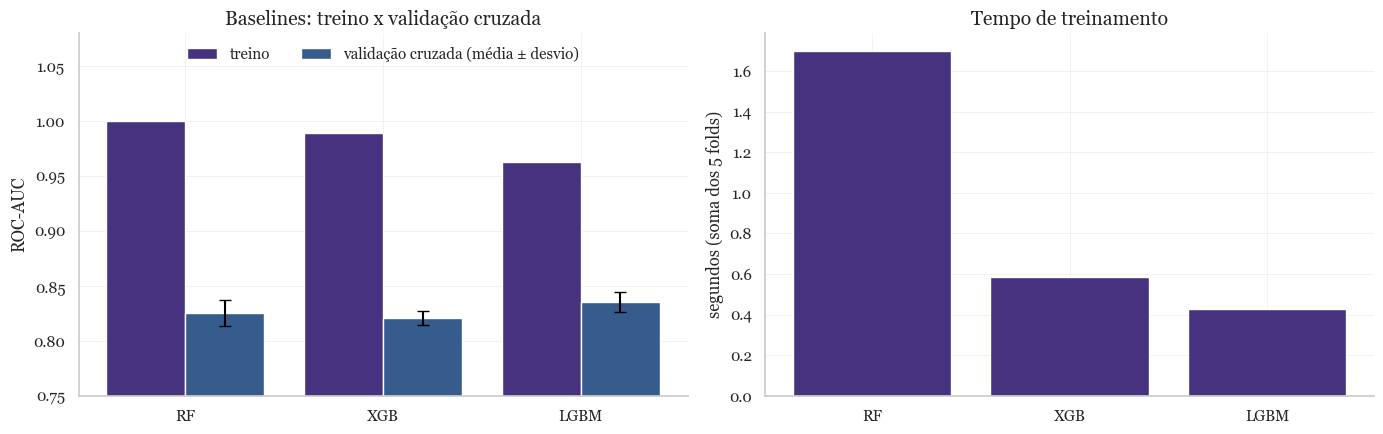

In [21]:
# comparação visual dos baselines: treino x validação cruzada e tempo de treinamento
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

posicoes = np.arange(len(tabela_baseline))
ax1.bar(posicoes - 0.2, tabela_baseline["AUC treino"], width=0.4, label="treino")
ax1.bar(posicoes + 0.2, tabela_baseline["AUC CV (média)"], width=0.4, yerr=tabela_baseline["AUC CV (desvio)"],
        capsize=4, label="validação cruzada (média ± desvio)")
ax1.set_xticks(posicoes, tabela_baseline.index)
ax1.set(ylim=(0.75, 1.08), ylabel="ROC-AUC", title="Baselines: treino x validação cruzada")
ax1.legend(loc="upper center", ncol=2)

ax2.bar(tabela_baseline.index, tabela_baseline["tempo de treino (s)"])
ax2.set(ylabel="segundos (soma dos 5 folds)", title="Tempo de treinamento")
plt.tight_layout()
plt.show()

**Comparação inicial (4.4).** A coluna "AUC treino" é a média da AUC nas partes de treino dos 5 folds, e o tempo é a soma dos 5 ajustes.

- **Os três baselines sobreajustam.** A AUC de treino fica entre 0,963 e 1,000, enquanto a de validação fica entre 0,821 e 0,836. O gap $\Delta_{\uparrow}$ é de 0,175 no Random Forest, 0,169 no XGBoost e 0,127 no LightGBM. O Random Forest praticamente decora o treino (0,9999) porque suas árvores crescem sem limite de profundidade; o XGBoost padrão combina profundidade 6 com taxa de aprendizado alta (0,3).
- **Não há sinal de underfitting:** nenhum modelo tem desempenho baixo no treino. O problema dos padrões é excesso de complexidade para uma base de 5,6 mil linhas.
- **Ranking na validação.** LightGBM (0,836 ± 0,009) fica à frente de Random Forest (0,825 ± 0,012) e XGBoost (0,821 ± 0,006). A diferença entre LightGBM e os outros é da ordem de um desvio-padrão entre folds, então é uma vantagem pequena, não uma separação clara. Também é o LightGBM o que tem menor gap.
- **Métricas auxiliares.** No limiar 0,5 os três apontam só cerca de metade dos cancelamentos (recall entre 0,49 e 0,52), com precisão entre 0,62 e 0,64.
- **Custo.** O Random Forest foi o mais lento dos três nesta execução, e os dois boostings treinam em menos tempo (valores na tabela; o tempo varia de uma execução para outra).

Conclusão desta etapa: a prioridade do tuning é **reduzir complexidade** (árvores mais rasas, folhas maiores, taxa de aprendizado menor), e não aumentar a capacidade.

<br>

---

<br>

### **Exercício 5 — Tuning com Grid Search e Optuna — 2,0 pontos**

Ajuste os hiperparâmetros de **cada um dos três modelos** usando duas estratégias distintas: Grid Search e Optuna. Todo tuning deve ocorrer exclusivamente sobre $\mathcal{D}_{\mathrm{treino}}$ e utilizar o protocolo de validação definido no Exercício 3.

O problema geral pode ser representado como a busca por um conjunto de hiperparâmetros $\boldsymbol{\theta}$ que otimiza a métrica de validação cruzada:

$$
\boldsymbol{\theta}^{\star}
=
\operatorname*{arg\,opt}_{\boldsymbol{\theta}\in\Theta}
\frac{1}{K}
\sum_{k=1}^{K}
S_k(\boldsymbol{\theta}),
$$

em que $\operatorname*{arg\,opt}$ significa maximizar uma métrica de desempenho ou minimizar uma função de erro, conforme a métrica principal adotada.

1. **Grid Search — 0,75 ponto.** Para $M_{\mathrm{RF}}$, $M_{\mathrm{XGB}}$ e $M_{\mathrm{LGBM}}$, defina uma grade coerente de hiperparâmetros, execute a busca e registre os melhores parâmetros, o score médio de validação e o custo computacional. A grade deve explorar parâmetros que controlem complexidade, número de árvores e/ou taxa de aprendizado, conforme o algoritmo.
2. **Optuna — 1,00 ponto.** Para os três modelos, defina uma função objetivo baseada na mesma métrica principal e nos mesmos dados de validação. Documente o espaço de busca, o número de trials e o melhor conjunto de hiperparâmetros. Como referência, utilize pelo menos 20 trials por modelo ou justifique claramente uma quantidade menor por restrição computacional.
3. **Comparação das estratégias — 0,25 ponto.** Compare Grid Search e Optuna em qualidade da solução, custo computacional e comportamento da busca. Não escolha uma estratégia apenas porque produziu um número ligeiramente melhor; discuta estabilidade e complexidade.

**Sugestões de gráficos:** curva ou mapa de scores do `cv_results_` do Grid Search para hiperparâmetros relevantes; histórico de otimização do Optuna; importância dos hiperparâmetros no Optuna; tempo de busca por modelo e estratégia.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Controle de comparabilidade:</strong> mantenha a métrica principal, a preparação dos dados e o esquema de validação tão consistentes quanto possível entre os três modelos. Se houver diferença de pipeline necessária por causa de uma biblioteca ou tipo de variável, explique a diferença e por que ela não invalida a comparação.
</div>

**Resposta do aluno — Exercício 5**


As duas estratégias usam o mesmo pipeline, os mesmos 5 folds e a mesma métrica (ROC-AUC), sempre e somente sobre $\mathcal{D}_{\mathrm{treino}}$.

**Grades do Grid Search.** Como os baselines sobreajustaram, as grades vão do padrão para o lado mais simples:

- **Random Forest:** `max_depth` (4, 8, 12, sem limite) e `min_samples_leaf` (1, 5, 20) controlam a complexidade de cada árvore; `n_estimators` (200, 500) o tamanho da floresta. 24 combinações.
- **XGBoost:** `max_depth` (2, 4, 6) para complexidade, `learning_rate` (0,03; 0,1; 0,3) e `n_estimators` (100, 300), que precisam ser ajustados em conjunto. 18 combinações.
- **LightGBM:** `num_leaves` (4, 8, 31) no lugar da profundidade, porque o LightGBM cresce a árvore por folha, mais `learning_rate` e `n_estimators` iguais aos do XGBoost. 18 combinações.

In [22]:
# Resposta do aluno - exercício 5
import time

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

# 5.1 Grid Search: grades com complexidade, número de árvores e taxa de aprendizado
grades = {
    "RF": {
        "modelo__n_estimators": [200, 500],
        "modelo__max_depth": [4, 8, 12, None],
        "modelo__min_samples_leaf": [1, 5, 20],
    },
    "XGB": {
        "modelo__n_estimators": [100, 300],
        "modelo__learning_rate": [0.03, 0.1, 0.3],
        "modelo__max_depth": [2, 4, 6],
    },
    "LGBM": {
        "modelo__n_estimators": [100, 300],
        "modelo__learning_rate": [0.03, 0.1, 0.3],
        "modelo__num_leaves": [4, 8, 31],
    },
}

buscas_grid, tempo_grid = {}, {}
for nome, modelo in baselines.items():
    busca = GridSearchCV(montar_pipeline(clone(modelo)), grades[nome], scoring=METRICA, cv=cv,
                         n_jobs=-1, refit=False, return_train_score=True)
    inicio = time.perf_counter()
    busca.fit(X_treino, y_treino)
    tempo_grid[nome] = time.perf_counter() - inicio
    buscas_grid[nome] = busca

tabela_grid = pd.DataFrame({
    nome: {
        "combinações avaliadas": len(busca.cv_results_["params"]),
        "melhores hiperparâmetros": {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()},
        "AUC CV (média)": round(busca.best_score_, 4),
        "tempo de busca (s)": round(tempo_grid[nome], 1),
    }
    for nome, busca in buscas_grid.items()
}).T
pd.set_option("display.max_colwidth", None)
tabela_grid

,combinações avaliadas,melhores hiperparâmetros,AUC CV (média),tempo de busca (s)
RF,24,"{'max_depth': 8, 'min_samples_leaf': 20, 'n_estimators': 200}",0.8484,23.6
XGB,18,"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}",0.8493,3.4
LGBM,18,"{'learning_rate': 0.03, 'n_estimators': 300, 'num_leaves': 4}",0.8486,2.8


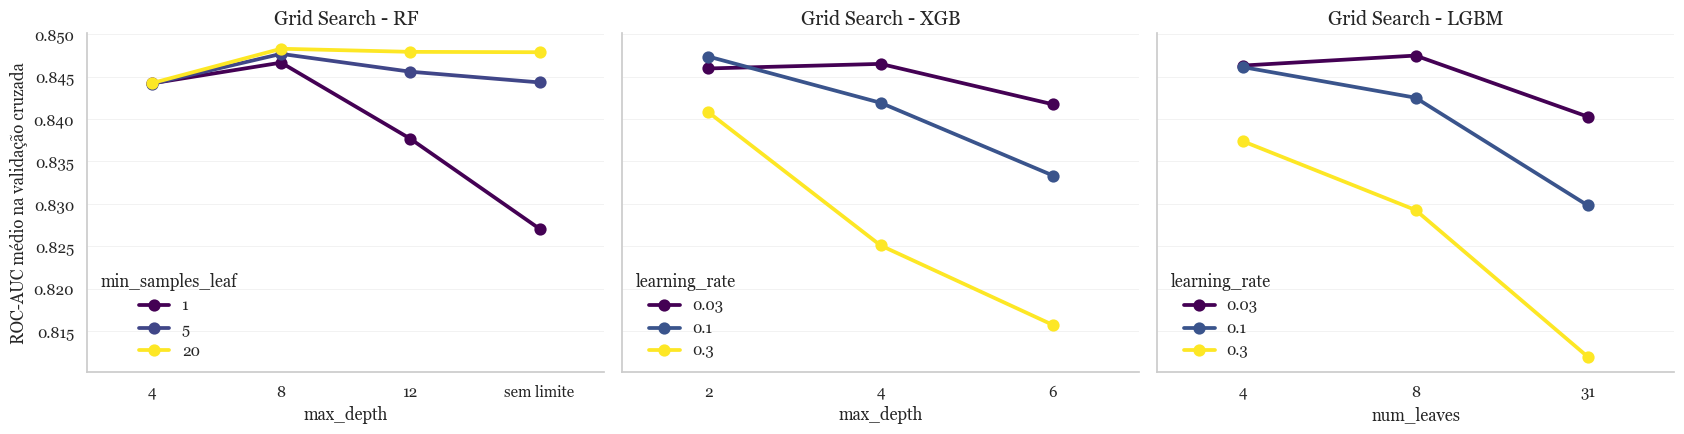

In [23]:
# resultados do cv_results_: efeito da complexidade em cada modelo (média sobre o número de árvores)
eixos_grid = {
    "RF": ("param_modelo__max_depth", "param_modelo__min_samples_leaf"),
    "XGB": ("param_modelo__max_depth", "param_modelo__learning_rate"),
    "LGBM": ("param_modelo__num_leaves", "param_modelo__learning_rate"),
}

fig, eixos = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (nome, (param_x, param_cor)) in zip(eixos, eixos_grid.items()):
    resultados = pd.DataFrame(buscas_grid[nome].cv_results_)
    chave = param_x.replace("param_", "")
    resultados[param_x] = ["sem limite" if p[chave] is None else str(p[chave]) for p in resultados["params"]]
    sns.pointplot(data=resultados, x=param_x, y="mean_test_score", hue=param_cor, errorbar=None, palette="viridis", ax=ax)
    ax.set(title=f"Grid Search - {nome}", xlabel=param_x.replace("param_modelo__", ""), ylabel="ROC-AUC médio na validação cruzada")
    ax.legend(title=param_cor.replace("param_modelo__", ""))
plt.tight_layout()
plt.show()

**Resultado do Grid Search (5.1).** Os três modelos chegam praticamente ao mesmo ponto, AUC de validação entre 0,848 e 0,849, bem acima dos baselines (0,821 a 0,836). Os melhores parâmetros confirmam a leitura do Exercício 4: **árvores bem simples**. O XGBoost ficou com profundidade 2, o LightGBM com 4 folhas e o Random Forest com profundidade 8 e folhas de pelo menos 20 clientes.

O gráfico do `cv_results_` mostra o comportamento da busca:

- **XGBoost e LightGBM:** a AUC cai conforme a árvore fica mais complexa, e cai mais rápido quanto maior a taxa de aprendizado. A pior região é complexidade alta com `learning_rate = 0,3` (AUC entre 0,81 e 0,82), que no XGBoost corresponde exatamente aos valores padrão.
- **Random Forest:** profundidade 4 fica um pouco abaixo do melhor (0,844), sinal de leve underfitting; a partir de 8, o que decide é o tamanho mínimo da folha. Com folhas de 20 clientes a AUC se mantém perto de 0,848 mesmo sem limite de profundidade; com folha de 1 ela cai para 0,827.

O custo do Random Forest foi várias vezes maior que o dos boostings (tabela), por ter mais combinações e florestas de até 500 árvores profundas.

In [24]:
# 5.2 Optuna: mesma métrica, mesmos folds e mesmo pipeline do Grid Search
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 30


def espaco_rf(trial):
    return RandomForestClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
        max_depth=trial.suggest_int("max_depth", 3, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 30),
        max_features=trial.suggest_float("max_features", 0.2, 1.0),
        random_state=SEED, n_jobs=1,
    )


def espaco_xgb(trial):
    return XGBClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 0.01, 10.0, log=True),
        random_state=SEED, n_jobs=1,
    )


def espaco_lgbm(trial):
    return LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 64),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 100),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 0.01, 10.0, log=True),
        random_state=SEED, n_jobs=1, verbose=-1,
    )


espacos = {"RF": espaco_rf, "XGB": espaco_xgb, "LGBM": espaco_lgbm}


def criar_objetivo(espaco):
    def objetivo(trial):
        scores = cross_val_score(montar_pipeline(espaco(trial)), X_treino, y_treino, cv=cv, scoring=METRICA, n_jobs=-1)
        trial.set_user_attr("desvio", scores.std())
        return scores.mean()
    return objetivo


estudos, tempo_optuna = {}, {}
for nome, espaco in espacos.items():
    estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    inicio = time.perf_counter()
    estudo.optimize(criar_objetivo(espaco), n_trials=N_TRIALS)
    tempo_optuna[nome] = time.perf_counter() - inicio
    estudos[nome] = estudo

tabela_optuna = pd.DataFrame({
    nome: {
        "trials": len(estudo.trials),
        "melhores hiperparâmetros": {k: round(v, 4) if isinstance(v, float) else v for k, v in estudo.best_params.items()},
        "AUC CV (média)": round(estudo.best_value, 4),
        "trial do melhor resultado": estudo.best_trial.number + 1,
        "tempo de busca (s)": round(tempo_optuna[nome], 1),
    }
    for nome, estudo in estudos.items()
}).T
tabela_optuna

,trials,melhores hiperparâmetros,AUC CV (média),trial do melhor resultado,tempo de busca (s)
RF,30,"{'n_estimators': 350, 'max_depth': 7, 'min_samples_leaf': 14, 'max_features': 0.2688}",0.8484,20,46.9
XGB,30,"{'n_estimators': 500, 'learning_rate': 0.024, 'max_depth': 2, 'min_child_weight': 6, 'subsample': 0.839, 'colsample_bytree': 0.637, 'reg_lambda': 0.0589}",0.8496,25,10.0
LGBM,30,"{'n_estimators': 500, 'learning_rate': 0.0164, 'num_leaves': 5, 'min_child_samples': 91, 'colsample_bytree': 0.9012, 'reg_lambda': 6.5266}",0.8493,29,9.0


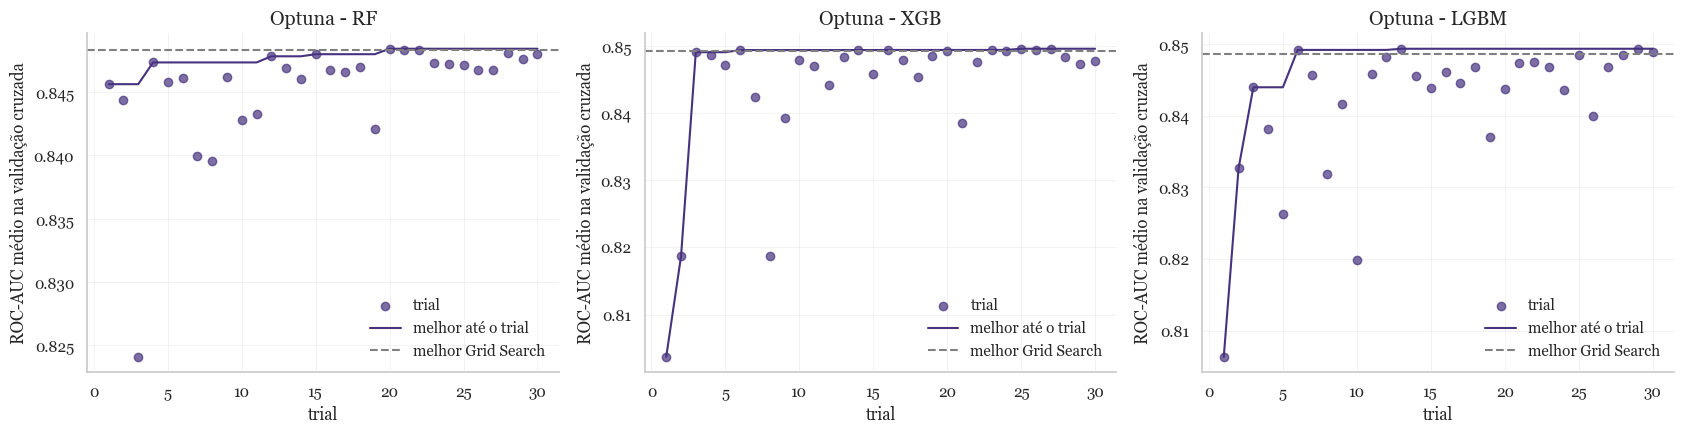

In [25]:
# histórico de otimização do Optuna, com o melhor Grid Search como referência
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (nome, estudo) in zip(eixos, estudos.items()):
    valores = pd.Series([t.value for t in estudo.trials], index=range(1, len(estudo.trials) + 1))
    ax.scatter(valores.index, valores, label="trial", alpha=0.7)
    ax.plot(valores.cummax(), label="melhor até o trial")
    ax.axhline(buscas_grid[nome].best_score_, color="gray", linestyle="--", label="melhor Grid Search")
    ax.set(title=f"Optuna - {nome}", xlabel="trial", ylabel="ROC-AUC médio na validação cruzada")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

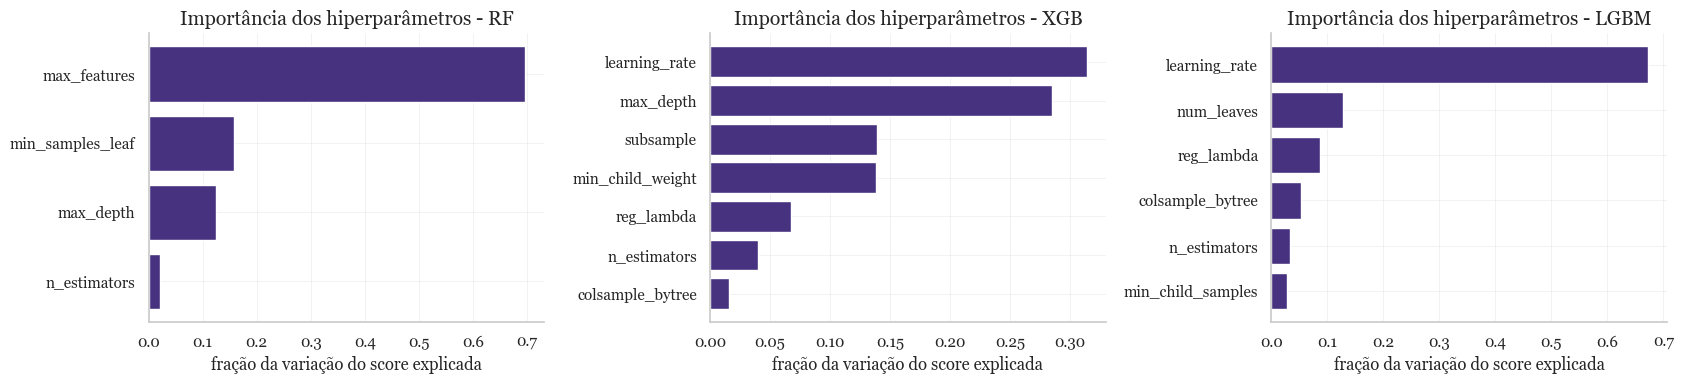

In [26]:
# importância dos hiperparâmetros no Optuna (fANOVA)
from optuna.importance import FanovaImportanceEvaluator, get_param_importances

fig, eixos = plt.subplots(1, 3, figsize=(17, 4))
for ax, (nome, estudo) in zip(eixos, estudos.items()):
    importancias = pd.Series(get_param_importances(estudo, evaluator=FanovaImportanceEvaluator(seed=SEED))).sort_values()
    ax.barh(importancias.index, importancias.values)
    ax.set(title=f"Importância dos hiperparâmetros - {nome}", xlabel="fração da variação do score explicada")
plt.tight_layout()
plt.show()

**Optuna (5.2).** A função objetivo devolve a média da ROC-AUC nos mesmos 5 folds do Grid Search, com o mesmo pipeline. Usei **30 trials por modelo** (acima da referência de 20) com o amostrador TPE e semente fixa, para o estudo ser reproduzível.

**Espaço de busca.** Diferente da grade, os intervalos são contínuos e incluem hiperparâmetros que o Grid Search não cobriu:

| Modelo | Espaço de busca |
|---|---|
| Random Forest | `n_estimators` 100–600 (passo 50), `max_depth` 3–20, `min_samples_leaf` 1–30, `max_features` 0,2–1,0 |
| XGBoost | `n_estimators` 100–600, `learning_rate` 0,01–0,3 (escala log), `max_depth` 2–8, `min_child_weight` 1–10, `subsample` 0,6–1,0, `colsample_bytree` 0,6–1,0, `reg_lambda` 0,01–10 (log) |
| LightGBM | `n_estimators` 100–600, `learning_rate` 0,01–0,3 (log), `num_leaves` 4–64, `min_child_samples` 10–100, `colsample_bytree` 0,6–1,0, `reg_lambda` 0,01–10 (log) |

**Resultado.** As melhores AUCs foram 0,848 (RF), 0,850 (XGBoost) e 0,849 (LightGBM). As soluções encontradas apontam na mesma direção do Grid Search: XGBoost com profundidade 2 e LightGBM com 5 folhas, ambos com taxa de aprendizado baixa (em torno de 0,02) compensada por 500 árvores; Random Forest com profundidade 7 e folhas de 14 clientes.

No histórico de otimização, XGBoost e LightGBM alcançam o nível do melhor Grid Search (linha tracejada) em menos de 10 trials e depois só oscilam em torno dele. O melhor trial aparece tarde (20º, 25º e 29º), mas com ganho na quarta casa decimal: é ruído de busca, não uma região nova.

A importância dos hiperparâmetros (fANOVA) mostra o que de fato move o score: `learning_rate` e `max_depth` no XGBoost, `learning_rate` no LightGBM e `max_features` no Random Forest. O número de árvores tem importância baixa nos três, então o custo extra de florestas grandes não se paga aqui.

configurações avaliadas  melhor AUC CV  \
modelo estratégia                                            
RF     Grid Search                       24         0.8484   
       Optuna                            30         0.8484   
XGB    Grid Search                       18         0.8493   
       Optuna                            30         0.8496   
LGBM   Grid Search                       18         0.8486   
       Optuna                            30         0.8493   

                    desvio entre folds  pior AUC CV da busca  \
modelo estratégia                                              
RF     Grid Search              0.0104                0.8270   
       Optuna                   0.0105                0.8241   
XGB    Grid Search              0.0119                0.8106   
       Optuna                   0.0116                0.8037   
LGBM   Grid Search              0.0114                0.8075   
       Optuna                   0.0119                0.8064   

                    configurações equivalentes à melhor  tempo de busca (s)  
modelo estratégia                                                            
RF     Grid Search                                   10             23.6464  
       Optuna                                        18             46.9159  
XGB    Grid Search                                    2              3.3905  
       Optuna                                        18              9.9958  
LGBM   Grid Search                                    4              2.7817  
       Optuna                                         9              9.0465

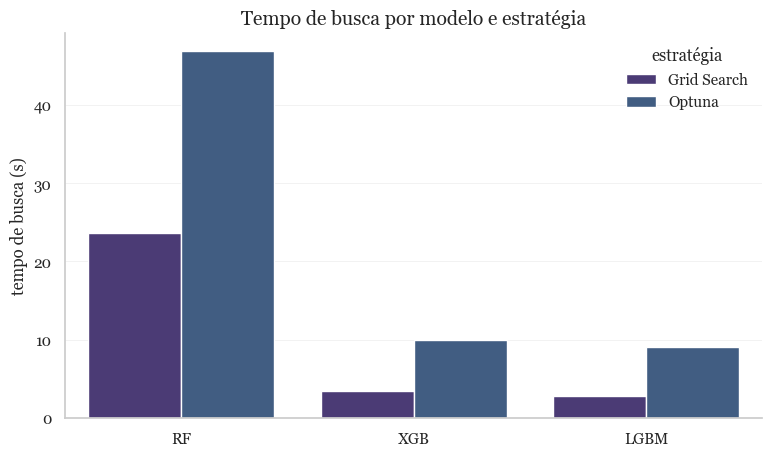

In [27]:
# 5.3 comparação das duas estratégias: qualidade, estabilidade e custo
TOLERANCIA = 0.002   # configurações a até 0,002 de AUC da melhor são consideradas equivalentes

linhas = []
for nome in baselines:
    busca, estudo = buscas_grid[nome], estudos[nome]
    scores_grid = pd.Series(busca.cv_results_["mean_test_score"])
    scores_optuna = pd.Series([t.value for t in estudo.trials])
    linhas.append({
        "modelo": nome, "estratégia": "Grid Search", "configurações avaliadas": len(scores_grid),
        "melhor AUC CV": busca.best_score_, "desvio entre folds": busca.cv_results_["std_test_score"][busca.best_index_],
        "pior AUC CV da busca": scores_grid.min(),
        "configurações equivalentes à melhor": int((scores_grid >= scores_grid.max() - TOLERANCIA).sum()),
        "tempo de busca (s)": tempo_grid[nome],
    })
    linhas.append({
        "modelo": nome, "estratégia": "Optuna", "configurações avaliadas": len(scores_optuna),
        "melhor AUC CV": estudo.best_value, "desvio entre folds": estudo.best_trial.user_attrs["desvio"],
        "pior AUC CV da busca": scores_optuna.min(),
        "configurações equivalentes à melhor": int((scores_optuna >= scores_optuna.max() - TOLERANCIA).sum()),
        "tempo de busca (s)": tempo_optuna[nome],
    })

comparacao_buscas = pd.DataFrame(linhas).set_index(["modelo", "estratégia"])
display(comparacao_buscas.round(4))

ax = sns.barplot(data=comparacao_buscas.reset_index(), x="modelo", y="tempo de busca (s)", hue="estratégia")
ax.set(title="Tempo de busca por modelo e estratégia", xlabel="")
plt.show()

**Comparação das estratégias (5.3).**

- **Qualidade da solução.** Empate técnico. O Optuna ficou à frente do Grid Search por 0,0003 no XGBoost e 0,0007 no LightGBM, e empatou no Random Forest. O desvio-padrão entre folds é de cerca de 0,011, de 15 a 40 vezes maior que essas diferenças. Não há base para dizer que uma estratégia achou uma solução melhor que a outra.
- **Custo computacional.** O Optuna levou mais tempo nos três modelos (tabela e gráfico). Ele avaliou mais configurações (30 contra 18 ou 24), várias delas com muitas árvores, e roda um trial de cada vez, porque cada sugestão depende dos resultados anteriores; o Grid Search distribui todas as combinações entre os núcleos da máquina.
- **Estabilidade.** O desvio entre folds da melhor configuração é igual nas duas (0,010 a 0,012). Olhando a busca inteira, o Optuna concentrou mais avaliações na região boa: 18 de 30 trials do XGBoost ficaram a até 0,002 do melhor, contra 2 de 18 combinações da grade. Isso mostra que o TPE aprendeu onde procurar e que a região ótima é larga, não um ponto isolado.
- **Comportamento da busca.** O Grid Search é exaustivo e fácil de explicar, mas só enxerga os valores que eu escolhi; gastou parte do orçamento em combinações claramente ruins (taxa 0,3 com árvores profundas). O Optuna explora intervalos contínuos e mais hiperparâmetros, converge em poucos trials e depois refina sem ganho relevante.

Para esta base, a grade pequena e bem direcionada pelo diagnóstico do Exercício 4 foi suficiente. O Optuna serviu mais como confirmação de que não existe uma região melhor fora da grade do que como fonte de ganho. A escolha da configuração final não se baseia em qual estratégia a produziu, e sim nos critérios do Exercício 6.

<br>

---

<br>

### **Exercício 6 — Escolha do melhor modelo e análise de overfitting/underfitting — 1,5 ponto**

Com base apenas nos resultados de treinamento e validação cruzada, escolha a configuração que será promovida a modelo final. A escolha deve considerar desempenho, variabilidade entre folds, diferença entre treino e validação, custo e complexidade.

1. **Seleção do modelo — 0,50 ponto.** Construa uma tabela final com, no mínimo, as nove configurações principais: baseline, melhor Grid Search e melhor Optuna para cada um dos três algoritmos. Defina qual configuração será levada ao teste final e justifique a decisão.
2. **Overfitting e underfitting — 0,50 ponto.** Compare desempenho de treino e validação e produza uma **curva de aprendizado** para a configuração escolhida. Discuta se há evidências de overfitting, underfitting ou comportamento compatível com boa generalização.
3. **Interpretação do comportamento do modelo — 0,50 ponto.** Produza um gráfico de importância das variáveis para o modelo escolhido e pelo menos um gráfico de desempenho adequado ao tipo de problema:
   - **classificação:** matriz de confusão e, quando pertinente, curva ROC ou Precision–Recall;
   - **regressão:** valores observados versus previstos e/ou análise de resíduos.

Para uma métrica em que valores maiores representam melhor desempenho, um indício simples de sobreajuste pode ser observado pelo gap

$$
\Delta_{\uparrow}=S_{\mathrm{treino}}-S_{\mathrm{CV}}.
$$

Para uma função de erro em que valores menores são melhores, considere

$$
\Delta_{\downarrow}=L_{\mathrm{CV}}-L_{\mathrm{treino}}.
$$

Um gap elevado pode indicar sobreajuste, mas a conclusão deve considerar também a curva de aprendizado, a variabilidade dos folds e a escala da métrica.

**Resposta do aluno — Exercício 6**


As nove configurações (baseline, melhor Grid Search e melhor Optuna de cada algoritmo) são reavaliadas pela mesma função `avaliar` do Exercício 4, nos mesmos folds. Nada do conjunto de teste entra nesta etapa.

In [28]:
# Resposta do aluno - exercício 6
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
from sklearn.model_selection import cross_val_predict, learning_curve

# 6.1 as nove configurações, todas avaliadas pela mesma função e pelos mesmos folds
configuracoes, hiperparametros = {}, {}
for nome in baselines:
    melhores_grid = {k.replace("modelo__", ""): v for k, v in buscas_grid[nome].best_params_.items()}
    configuracoes[f"{nome} - baseline"] = baselines[nome]
    configuracoes[f"{nome} - Grid Search"] = clone(baselines[nome]).set_params(**melhores_grid)
    configuracoes[f"{nome} - Optuna"] = espacos[nome](optuna.trial.FixedTrial(estudos[nome].best_params))
    hiperparametros[f"{nome} - baseline"] = {h: baselines[nome].get_params()[h] for h in HIPERPARAMETROS[nome]}
    hiperparametros[f"{nome} - Grid Search"] = melhores_grid
    hiperparametros[f"{nome} - Optuna"] = estudos[nome].best_params

tabela_final = pd.DataFrame([avaliar(nome, modelo) for nome, modelo in configuracoes.items()]).set_index("configuração")
tabela_final.sort_values("AUC CV (média)", ascending=False).round(4)

,AUC treino,AUC CV (média),AUC CV (desvio),gap (treino - CV),tempo de treino (s),F1 CV,recall CV,precisão CV,acurácia CV
configuração,,,,,,,,,
XGB - Optuna,0.8653,0.8496,0.0116,0.0156,1.2292,0.5945,0.5344,0.6711,0.8067
LGBM - Optuna,0.8660,0.8493,0.0119,0.0167,0.7742,0.5998,0.5391,0.6767,0.8090
XGB - Grid Search,0.8633,0.8493,0.0119,0.0139,0.3360,0.5886,0.5264,0.6687,0.8046
LGBM - Grid Search,0.8650,0.8486,0.0114,0.0163,0.5026,0.5866,0.5251,0.6658,0.8035
RF - Optuna,0.8794,0.8484,0.0105,0.0310,4.1054,0.5666,0.4883,0.6764,0.8016
RF - Grid Search,0.8772,0.8484,0.0104,0.0288,2.2697,0.5641,0.4836,0.6787,0.8016
LGBM - baseline,0.9629,0.8358,0.0091,0.1270,0.4655,0.5766,0.5231,0.6428,0.7961
RF - baseline,0.9999,0.8252,0.0118,0.1747,1.8027,0.5545,0.4890,0.6407,0.7914
XGB - baseline,0.9894,0.8208,0.0064,0.1686,0.4979,0.5612,0.5151,0.6169,0.7861


In [29]:
# regra de escolha: entre as configurações estatisticamente empatadas com a de maior AUC na validação
# (até um erro-padrão abaixo dela), fica a que tem o menor gap entre treino e validação
melhor_cv = tabela_final["AUC CV (média)"].idxmax()
erro_padrao = tabela_final.loc[melhor_cv, "AUC CV (desvio)"] / np.sqrt(cv.get_n_splits())
limite = tabela_final.loc[melhor_cv, "AUC CV (média)"] - erro_padrao

candidatas = tabela_final[tabela_final["AUC CV (média)"] >= limite]
ESCOLHIDA = candidatas["gap (treino - CV)"].idxmin()

print(f"Maior AUC na validação cruzada: {melhor_cv} ({tabela_final.loc[melhor_cv, 'AUC CV (média)']:.4f})")
print(f"Limite de um erro-padrão: {limite:.4f}")
print(f"Configuração escolhida: {ESCOLHIDA}")
print("Hiperparâmetros:", hiperparametros[ESCOLHIDA])
candidatas[["AUC treino", "AUC CV (média)", "AUC CV (desvio)", "gap (treino - CV)", "tempo de treino (s)"]].round(4)

Maior AUC na validação cruzada: XGB - Optuna (0.8496)
Limite de um erro-padrão: 0.8444
Configuração escolhida: XGB - Grid Search
Hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}


,AUC treino,AUC CV (média),AUC CV (desvio),gap (treino - CV),tempo de treino (s)
configuração,,,,,
RF - Grid Search,0.8772,0.8484,0.0104,0.0288,2.2697
RF - Optuna,0.8794,0.8484,0.0105,0.0310,4.1054
XGB - Grid Search,0.8633,0.8493,0.0119,0.0139,0.3360
XGB - Optuna,0.8653,0.8496,0.0116,0.0156,1.2292
LGBM - Grid Search,0.8650,0.8486,0.0114,0.0163,0.5026
LGBM - Optuna,0.8660,0.8493,0.0119,0.0167,0.7742


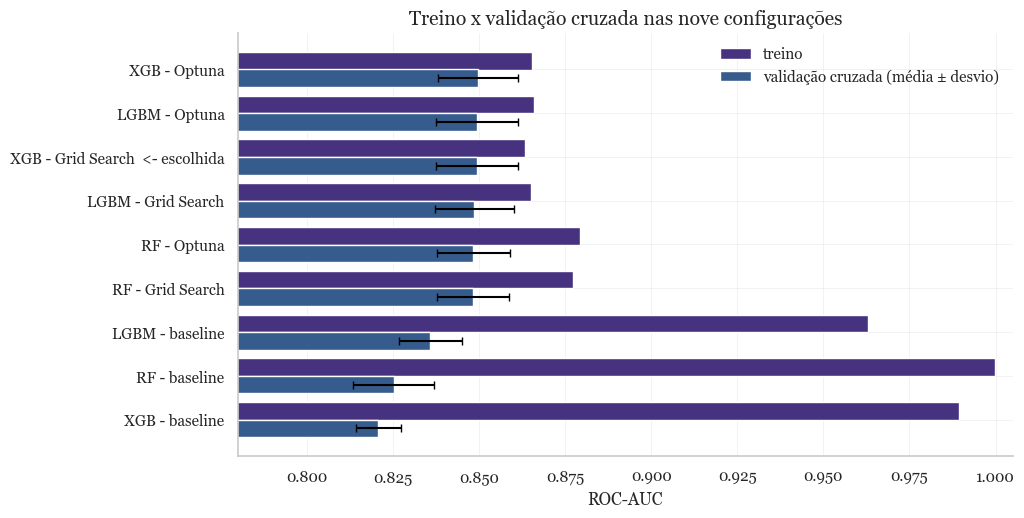

In [30]:
# visão geral das nove configurações: treino x validação cruzada
ordenada = tabela_final.sort_values("AUC CV (média)")
posicoes = np.arange(len(ordenada))

plt.figure(figsize=(10, 5.5))
plt.barh(posicoes + 0.2, ordenada["AUC treino"], height=0.4, label="treino")
plt.barh(posicoes - 0.2, ordenada["AUC CV (média)"], height=0.4, xerr=ordenada["AUC CV (desvio)"], capsize=3,
         label="validação cruzada (média ± desvio)")
plt.yticks(posicoes, [f"{nome}  <- escolhida" if nome == ESCOLHIDA else nome for nome in ordenada.index])
plt.xlim(0.78, 1.005)
plt.xlabel("ROC-AUC")
plt.title("Treino x validação cruzada nas nove configurações")
plt.legend(loc="upper right")
plt.show()

**Seleção do modelo (6.1).** A tabela mostra dois grupos bem separados:

- os **três baselines**, com AUC de validação entre 0,821 e 0,836 e gap entre 0,127 e 0,175;
- as **seis configurações ajustadas**, todas entre 0,848 e 0,850, com gap entre 0,014 e 0,031.

Dentro do segundo grupo, a maior diferença de AUC é 0,0012, cerca de um décimo do desvio entre folds. Escolher pelo maior número seria escolher pelo ruído. Por isso fixei uma regra antes de olhar o resultado: considero **empatadas** todas as configurações a até um erro-padrão da melhor (limite de 0,8444) e, entre elas, fico com a de **menor gap entre treino e validação**, que é a evidência mais direta de generalização.

A regra seleciona o **XGBoost do Grid Search** (`n_estimators=100`, `learning_rate=0,1`, `max_depth=2`):

- **Desempenho:** AUC de validação 0,8493 ± 0,0119, a 0,0003 da melhor.
- **Generalização:** menor gap das nove configurações (0,0139).
- **Complexidade:** 100 árvores de profundidade 2 é o modelo mais simples entre os candidatos. O XGBoost do Optuna precisa de 500 árvores e mais quatro hiperparâmetros ajustados para ganhar 0,0003.
- **Custo:** está entre os mais rápidos de treinar. As duas configurações de Random Forest são as mais lentas e têm o dobro do gap.
- **Variabilidade:** o desvio entre folds é parecido em todas as candidatas (0,010 a 0,012), então não diferencia.

No F1 e no recall, as duas configurações do Optuna ficam de 0,006 a 0,013 acima da escolhida. Mantive a decisão porque a métrica principal foi definida antes como a ROC-AUC, e trocar de critério depois de ver os resultados seria escolher a posteriori.

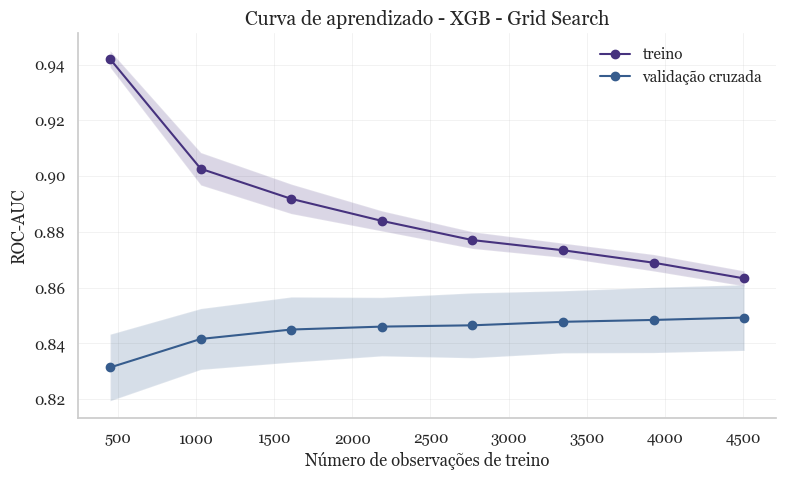

,observações de treino,AUC treino,AUC validação,desvio validação,gap
0,450,0.9420,0.8314,0.0119,0.1106
1,1030,0.9026,0.8416,0.0109,0.0610
2,1609,0.8918,0.8450,0.0117,0.0469
3,2189,0.8839,0.8460,0.0105,0.0379
4,2768,0.8771,0.8465,0.0117,0.0306
5,3348,0.8734,0.8477,0.0111,0.0257
6,3927,0.8689,0.8484,0.0117,0.0205
7,4507,0.8633,0.8493,0.0118,0.0140


In [31]:
# 6.2 curva de aprendizado da configuração escolhida
tamanhos, auc_treino, auc_validacao = learning_curve(
    montar_pipeline(clone(configuracoes[ESCOLHIDA])), X_treino, y_treino,
    cv=cv, scoring=METRICA, train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1,
)

curva = pd.DataFrame({
    "observações de treino": tamanhos,
    "AUC treino": auc_treino.mean(axis=1),
    "AUC validação": auc_validacao.mean(axis=1),
    "desvio validação": auc_validacao.std(axis=1),
})
curva["gap"] = curva["AUC treino"] - curva["AUC validação"]

plt.plot(tamanhos, curva["AUC treino"], marker="o", label="treino")
plt.fill_between(tamanhos, auc_treino.mean(axis=1) - auc_treino.std(axis=1), auc_treino.mean(axis=1) + auc_treino.std(axis=1), alpha=0.2)
plt.plot(tamanhos, curva["AUC validação"], marker="o", label="validação cruzada")
plt.fill_between(tamanhos, curva["AUC validação"] - curva["desvio validação"], curva["AUC validação"] + curva["desvio validação"], alpha=0.2)
plt.xlabel("Número de observações de treino")
plt.ylabel("ROC-AUC")
plt.title(f"Curva de aprendizado - {ESCOLHIDA}")
plt.legend()
plt.show()

curva.round(4)

**Overfitting e underfitting (6.2).**

- **Treino × validação.** Na configuração escolhida, a AUC é 0,863 no treino e 0,849 na validação, gap de 0,014, da mesma ordem do desvio entre folds (0,012). No baseline do mesmo algoritmo o gap era 0,169. O tuning eliminou o sobreajuste e ainda melhorou a validação em cerca de 0,03.
- **Curva de aprendizado.** Com 450 clientes o modelo sobreajusta (0,942 no treino e 0,831 na validação). Conforme entram mais dados, a AUC de treino cai e a de validação sobe, e o gap diminui de 0,111 para 0,014. As curvas convergem, que é o padrão esperado de um modelo que generaliza bem.
- **Underfitting?** As duas curvas se estabilizam perto de 0,85, então vale perguntar se o modelo é simples demais. A evidência diz que não: no Grid Search e no Optuna, árvores mais profundas ou com mais folhas **pioraram** a validação. Dar mais capacidade ao modelo não ajuda.
- **Mais dados ajudariam?** Pouco. A validação passa de 0,845 com 1,6 mil clientes para 0,849 com 4,5 mil. O limite parece estar na informação das variáveis disponíveis (não há, por exemplo, histórico de reclamações ou de uso), não no tamanho da amostra nem no algoritmo.

Conclusão: comportamento compatível com **boa generalização**, sem evidência de overfitting nem de underfitting relevante.

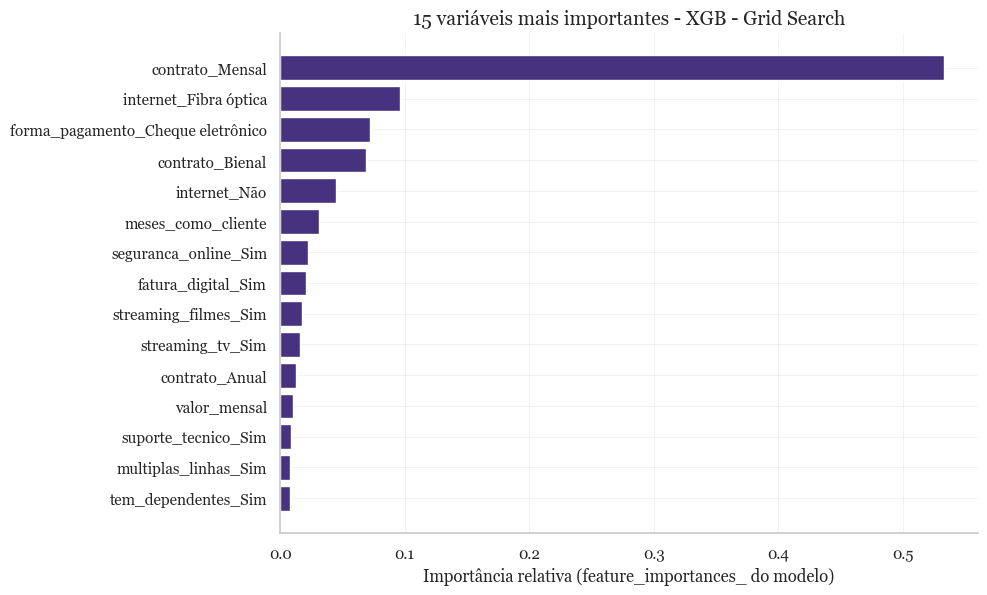

In [32]:
# 6.3 importância das variáveis: configuração escolhida ajustada em todo o D_treino
modelo_final = montar_pipeline(clone(configuracoes[ESCOLHIDA])).fit(X_treino, y_treino)

importancias = pd.Series(
    modelo_final.named_steps["modelo"].feature_importances_,
    index=modelo_final.named_steps["preparacao"].get_feature_names_out(),
).sort_values()
importancias = importancias / importancias.sum()

plt.figure(figsize=(9, 6.5))
plt.barh(importancias.index[-15:], importancias.values[-15:])
plt.xlabel("Importância relativa (feature_importances_ do modelo)")
plt.title(f"15 variáveis mais importantes - {ESCOLHIDA}")
plt.show()

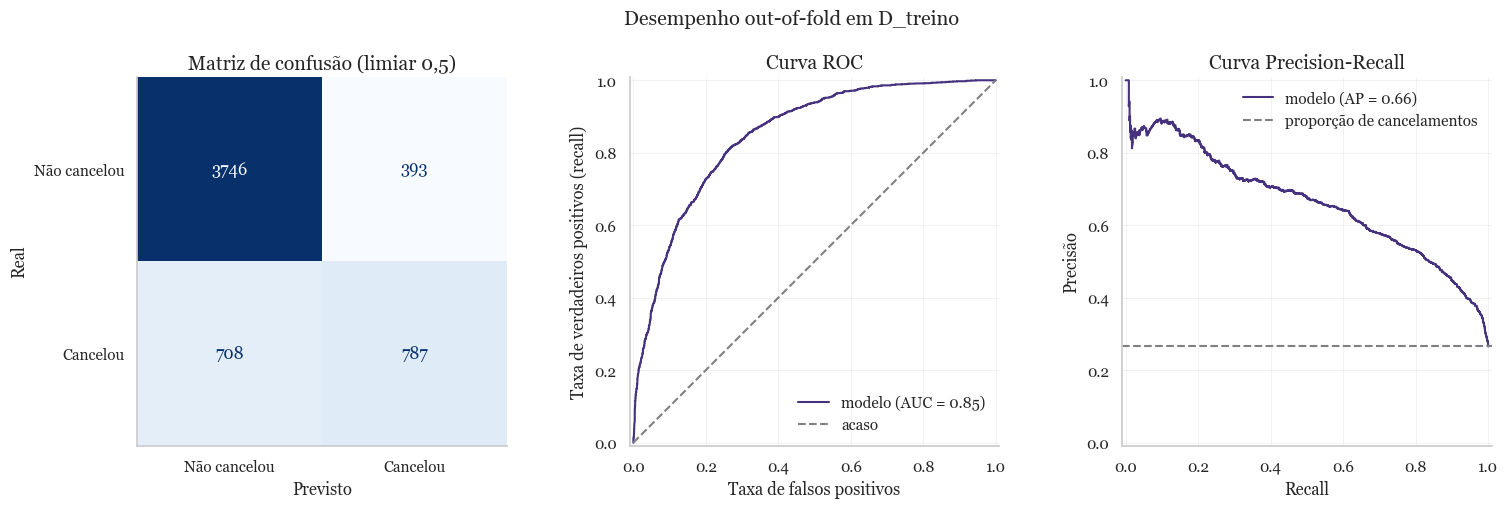

In [33]:
# 6.3 gráficos de desempenho com previsões out-of-fold: cada cliente do treino é previsto
# por um modelo que não o viu, então o conjunto de teste continua intocado
proba_oof = cross_val_predict(montar_pipeline(clone(configuracoes[ESCOLHIDA])), X_treino, y_treino,
                              cv=cv, method="predict_proba")[:, 1]
rotulos_classes = ["Não cancelou", "Cancelou"]

fig, eixos = plt.subplots(1, 3, figsize=(18, 4.8))
ConfusionMatrixDisplay.from_predictions(y_treino, (proba_oof >= 0.5).astype(int), display_labels=rotulos_classes,
                                        cmap="Blues", colorbar=False, ax=eixos[0])
eixos[0].grid(False)
eixos[0].set(title="Matriz de confusão (limiar 0,5)", xlabel="Previsto", ylabel="Real")

RocCurveDisplay.from_predictions(y_treino, proba_oof, name="modelo", ax=eixos[1])
eixos[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="acaso")
eixos[1].set(title="Curva ROC", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (recall)")
eixos[1].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(y_treino, proba_oof, name="modelo", ax=eixos[2])
eixos[2].axhline(y_treino.mean(), color="gray", linestyle="--", label="proporção de cancelamentos")
eixos[2].set(title="Curva Precision-Recall", xlabel="Recall", ylabel="Precisão")
eixos[2].legend(loc="upper right")

fig.suptitle("Desempenho out-of-fold em D_treino", y=1.02)
plt.show()

**Interpretação do modelo (6.3).**

*Importância das variáveis.* No XGBoost, `feature_importances_` é o ganho médio dos splits que usam cada variável, aqui normalizado para somar 1. `contrato_Mensal` concentra pouco mais da metade da importância, seguida de `internet_Fibra óptica`, `forma_pagamento_Cheque eletrônico`, `contrato_Bienal`, `internet_Não` e `meses_como_cliente`. É o mesmo perfil de risco encontrado na análise exploratória, o que indica que o modelo aprendeu padrões coerentes com os dados. Duas ressalvas: (i) `valor_total`, `meses_como_cliente` e o tipo de contrato são correlacionados, e a medida de ganho tende a concentrar o crédito na variável usada primeiro; (ii) importância indica uso pelo modelo, não causa. Não dá para concluir que mudar o contrato de um cliente evitaria o cancelamento.

*Desempenho out-of-fold.* Os gráficos usam previsões feitas dentro da validação cruzada: cada cliente do treino é previsto por um modelo que não o viu. O conjunto de teste continua intocado.

- **Matriz de confusão (limiar 0,5).** Dos 1.495 clientes que cancelaram, o modelo aponta 787 (recall de 0,53) e deixa passar 708. Dos 1.180 apontados como risco, 787 de fato cancelaram (precisão de 0,67). O modelo é conservador: erra mais por deixar de avisar do que por avisar à toa.
- **Curva ROC.** AUC de 0,85, bem acima do acaso. Aceitando cerca de 30% de falsos positivos, o modelo captura pouco mais de 80% dos cancelamentos.
- **Curva Precision–Recall.** Precisão média de 0,66, contra 0,27 da linha de base (proporção de cancelamentos). A curva mostra a troca disponível: baixar o limiar aumenta o recall ao custo de precisão.

Para uso real, o limiar deveria ser definido pelo custo de cada erro (contato de retenção desperdiçado × cliente perdido), usando estas previsões out-of-fold e nunca o teste. Neste trabalho mantenho 0,5, como definido no protocolo.

<br>

---

<br>

### **Exercício 7 — Teste final, consistência do modelo, entrega em produção e apresentação — 1,5 ponto**

Somente agora utilize $\mathcal{D}_{\mathrm{teste}}$. Refaça o treinamento da configuração selecionada usando todo $\mathcal{D}_{\mathrm{treino}}$ e execute a avaliação final uma única vez no conjunto de teste.

1. **Avaliação final — 0,50 ponto.** Calcule a métrica principal e as métricas auxiliares em $\mathcal{D}_{\mathrm{teste}}$. Compare o resultado de teste com a validação cruzada. Discuta se o desempenho final é compatível com o que era esperado durante o desenvolvimento.
2. **Teste de consistência — 0,40 ponto.** Selecione pelo menos cinco observações que não participaram do treinamento. Para cada uma, apresente as principais entradas, o valor real $y$, a previsão $\hat{y}$ e:
   - em classificação, a probabilidade prevista quando o estimador oferecer `predict_proba`;
   - em regressão, o erro individual $e_i=y_i-\hat{y}_i$.

   Interprete os casos e verifique se o comportamento do modelo é coerente com o padrão aprendido. Inclua pelo menos um caso em que o modelo acerta bem e um caso mais difícil, quando isso existir nos dados.
3. **GitHub e Streamlit — 0,60 ponto.** Disponibilize o projeto em um repositório GitHub e construa uma aplicação Streamlit que utilize **a mesma preparação de dados e o mesmo modelo final**. A interface deve receber as variáveis necessárias, gerar a previsão e apresentar o resultado de forma legível. O repositório deve conter, no mínimo:
   - `README.md` com descrição do problema, instruções de instalação e execução, links e resumo dos resultados;
   - notebook do CheckPoint05;
   - código da aplicação Streamlit;
   - arquivo de dependências (`requirements.txt` ou equivalente);
   - artefato do pipeline/modelo final ou código reproduzível para gerá-lo;
   - instruções para obtenção da base, caso ela não possa ser versionada no repositório.

Registre abaixo os links finais:

- **GitHub:** inserir URL do repositório.
- **Streamlit:** inserir URL da aplicação.

4. **Apresentação da solução — requisito obrigatório.** O grupo deverá realizar uma apresentação oral de **no máximo 10 minutos**. A exposição deve ser objetiva e demonstrar domínio sobre o desenvolvimento realizado. Organize a apresentação para contemplar, no mínimo:
   - problema escolhido, contexto, base de dados e variável-alvo;
   - principais decisões de data wrangling e escolha das variáveis;
   - comparação entre Random Forest, XGBoost e LightGBM;
   - resultados do Grid Search e do Optuna e justificativa da configuração final;
   - análise de overfitting e underfitting;
   - desempenho no conjunto de teste e principais conclusões sobre generalização;
   - demonstração breve da aplicação Streamlit e do teste de paridade entre notebook e interface.

A apresentação poderá utilizar slides ou a demonstração direta do projeto, desde que o tempo máximo seja respeitado. Todos os integrantes devem estar preparados para responder a perguntas sobre a solução desenvolvida.

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Teste adicional de paridade:</strong> escolha pelo menos uma das observações do teste de consistência, reproduza os mesmos valores de entrada na aplicação Streamlit e verifique se a previsão exibida pela interface coincide com a previsão produzida pelo pipeline no notebook. Divergências devem ser investigadas antes da entrega.
</div>

**Resposta do aluno — Exercício 7**


A partir daqui, e só aqui, $\mathcal{D}_{\mathrm{teste}}$ é usado. O modelo final é a configuração escolhida no Exercício 6, ajustada em todo o $\mathcal{D}_{\mathrm{treino}}$ (objeto `modelo_final`). A previsão no teste é calculada **uma única vez** (`proba_teste`), e tudo o que segue deriva dela.

In [34]:
# Resposta do aluno - exercício 7
import joblib
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

# 7.1 avaliação final: modelo ajustado em todo o D_treino (exercício 6) e uma única previsão em D_teste
proba_teste = modelo_final.predict_proba(X_teste)[:, 1]
previsao_teste = (proba_teste >= 0.5).astype(int)

metricas_teste = {
    "ROC-AUC": roc_auc_score(y_teste, proba_teste),
    "F1": f1_score(y_teste, previsao_teste),
    "recall": recall_score(y_teste, previsao_teste),
    "precisão": precision_score(y_teste, previsao_teste),
    "acurácia": accuracy_score(y_teste, previsao_teste),
}

linha_cv = tabela_final.loc[ESCOLHIDA]
teste_x_cv = pd.DataFrame({
    "validação cruzada": [linha_cv["AUC CV (média)"]] + [linha_cv[f"{nome} CV"] for nome in list(metricas_teste)[1:]],
    "teste": list(metricas_teste.values()),
}, index=list(metricas_teste))
teste_x_cv["diferença (teste - CV)"] = teste_x_cv["teste"] - teste_x_cv["validação cruzada"]

print(f"Modelo final: {ESCOLHIDA}")
print(f"AUC na validação cruzada: {linha_cv['AUC CV (média)']:.4f} ± {linha_cv['AUC CV (desvio)']:.4f}")
display(teste_x_cv.round(4))

pd.crosstab(y_teste.map({0: "Não cancelou", 1: "Cancelou"}).rename("real"),
            pd.Series(previsao_teste, index=y_teste.index).map({0: "Não cancelou", 1: "Cancelou"}).rename("previsto"))

Modelo final: XGB - Grid Search
AUC na validação cruzada: 0.8493 ± 0.0119


,validação cruzada,teste,diferença (teste - CV)
ROC-AUC,0.8493,0.8448,-0.0045
F1,0.5886,0.5727,-0.0159
recall,0.5264,0.5053,-0.0211
precisão,0.6687,0.6608,-0.0079
acurácia,0.8046,0.7999,-0.0047


previsto,Cancelou,Não cancelou
real,,
Cancelou,189,185
Não cancelou,97,938


**Avaliação final (7.1).** No teste, a ROC-AUC foi **0,8448**. Na validação cruzada era 0,8493 ± 0,0119. A diferença (−0,0045) é menor que meio desvio-padrão entre folds, ou seja, o teste se comportou como mais um fold. As métricas auxiliares contam a mesma história: F1 de 0,573 (0,589 na validação), recall de 0,505 (0,526), precisão de 0,661 (0,669) e acurácia de 0,800 (0,805). Todas ficam um pouco abaixo da validação, como é esperado, e nenhuma desaba.

Na matriz de confusão do teste, o modelo identificou 189 dos 374 cancelamentos e gerou 97 alertas falsos entre 1.035 clientes que ficaram, proporções parecidas com as das previsões out-of-fold.

O resultado final é **compatível com o que o desenvolvimento indicava**: gap pequeno entre treino e validação, curva de aprendizado convergente e, agora, teste dentro da faixa de variação dos folds. As três evidências apontam para a mesma conclusão, a de que o modelo generaliza para clientes novos da mesma população com AUC em torno de 0,85. A limitação já conhecida também se confirma: no limiar 0,5, metade dos cancelamentos não é sinalizada.

In [35]:
# 7.2 teste de consistência com cinco clientes do conjunto de teste
resultado = X_teste.assign(y_real=y_teste, probabilidade=proba_teste, y_previsto=previsao_teste)
resultado["erro"] = (resultado["y_real"] - resultado["probabilidade"]).abs()

cancelaram, ficaram = resultado[resultado["y_real"] == 1], resultado[resultado["y_real"] == 0]
casos = {
    "cancelamento previsto com mais segurança": cancelaram["erro"].idxmin(),
    "permanência prevista com mais segurança": ficaram["erro"].idxmin(),
    "caso de fronteira (probabilidade perto de 0,5)": (resultado["probabilidade"] - 0.5).abs().idxmin(),
    "cancelamento que o modelo não previu": cancelaram["erro"].idxmax(),
    "permanência prevista como cancelamento": ficaram["erro"].idxmax(),
}

consistencia = resultado.loc[list(casos.values())].drop(columns="erro")
consistencia.insert(0, "caso", list(casos.keys()))
consistencia["acertou"] = (consistencia["y_real"] == consistencia["y_previsto"]).map({True: "sim", False: "não"})

principais = ["caso", "meses_como_cliente", "contrato", "internet", "forma_pagamento", "valor_mensal",
              "y_real", "y_previsto", "probabilidade", "acertou"]
consistencia[principais].round(4)

,caso,meses_como_cliente,contrato,internet,forma_pagamento,valor_mensal,y_real,y_previsto,probabilidade,acertou
3380,cancelamento previsto com mais segurança,1,Mensal,Fibra óptica,Cheque eletrônico,95.10,1,1,0.9017,sim
5613,permanência prevista com mais segurança,72,Bienal,DSL,Transferência bancária (automática),70.45,0,0,0.0064,sim
1114,"caso de fronteira (probabilidade perto de 0,5)",32,Mensal,Fibra óptica,Cartão de crédito (automático),98.85,0,1,0.5009,não
4513,cancelamento que o modelo não previu,72,Bienal,DSL,Cartão de crédito (automático),92.45,1,0,0.0094,não
5905,permanência prevista como cancelamento,1,Mensal,Fibra óptica,Cheque eletrônico,85.00,0,1,0.8348,não


**Teste de consistência (7.2).** Os cinco clientes são do conjunto de teste e foram selecionados por regra, não à mão: os dois acertos mais seguros (um de cada classe), o caso mais próximo do limiar e os dois maiores erros (um de cada classe).

- **Índice 3380 (acerto claro).** Cliente com 1 mês de casa, contrato mensal, fibra e cheque eletrônico: $\hat{p}=0{,}90$ e ele de fato cancelou. É exatamente o perfil de maior risco da análise exploratória.
- **Índice 5613 (acerto claro).** 72 meses, contrato bienal, DSL, pagamento automático: $\hat{p}=0{,}006$ e ele ficou. O oposto do anterior.
- **Índice 1114 (fronteira).** 32 meses, mas contrato mensal com fibra e a mensalidade mais alta dos cinco: sinais nos dois sentidos, $\hat{p}=0{,}5009$. O modelo previu cancelamento por 0,0009 e errou. Mostra como a classificação é frágil perto do limiar, e por que faz mais sentido usar a probabilidade para ordenar clientes do que tratar o 0/1 como certeza.
- **Índice 4513 (caso difícil, falso negativo).** 72 meses e contrato bienal, perfil quase idêntico ao do 5613, e mesmo assim cancelou. O modelo deu $\hat{p}=0{,}009$. Nada nas variáveis disponíveis distingue esse cliente de um cliente fiel; o motivo da saída está fora da base.
- **Índice 5905 (caso difícil, falso positivo).** 1 mês, mensal, fibra, cheque eletrônico: mesmo perfil do 3380, $\hat{p}=0{,}83$, mas não cancelou no período.

O comportamento é coerente com o padrão aprendido: a probabilidade sobe e desce na direção que os dados indicam (tempo de casa, contrato, internet, pagamento), e clientes parecidos recebem probabilidades parecidas. Os dois maiores erros não são falha de lógica do modelo. São clientes que agiram ao contrário do que o perfil sugere, e é esse tipo de caso que explica a AUC de 0,85 e não mais.

In [36]:
# 7.3 artefato do modelo final e exemplos para o teste de paridade com o Streamlit
joblib.dump(modelo_final, "modelo_final.joblib")
consistencia.drop(columns="acertou").to_csv("exemplos_paridade.csv", index_label="indice")

# o artefato salvo precisa reproduzir exatamente as probabilidades calculadas acima
modelo_carregado = joblib.load("modelo_final.joblib")
proba_artefato = modelo_carregado.predict_proba(X_teste.loc[consistencia.index])[:, 1]
assert np.allclose(proba_artefato, consistencia["probabilidade"])
print("O artefato salvo reproduz as cinco previsões do notebook.")

# entradas completas da observação usada no teste de paridade
INDICE_PARIDADE = consistencia.index[0]
print(f"\nObservação de paridade (índice {INDICE_PARIDADE}): probabilidade de cancelamento no notebook = "
      f"{consistencia.loc[INDICE_PARIDADE, 'probabilidade']:.4f}")
X_teste.loc[[INDICE_PARIDADE]].T

O artefato salvo reproduz as cinco previsões do notebook.

Observação de paridade (índice 3380): probabilidade de cancelamento no notebook = 0.9017


,3380
genero,Masculino
idoso,1
tem_conjuge,Sim
tem_dependentes,Não
meses_como_cliente,1
telefone,Sim
multiplas_linhas,Sim
internet,Fibra óptica
seguranca_online,Não
backup_online,Não


**GitHub e Streamlit (7.3).** O pipeline completo (one-hot + XGBoost) ajustado em $\mathcal{D}_{\mathrm{treino}}$ é salvo em `modelo_final.joblib`. A aplicação (`app.py`) carrega esse arquivo e chama `predict_proba` sobre os valores digitados. Ela não refaz nenhuma preparação por conta própria, e as opções de cada campo vêm das categorias aprendidas pelo próprio pipeline; por isso a preparação de dados e o modelo são os mesmos do notebook. A célula acima também confere que o artefato salvo reproduz as cinco probabilidades do teste de consistência.

**Teste de paridade.** As cinco observações do teste de consistência ficam em `exemplos_paridade.csv`. Na aplicação, ao escolher o cliente de índice **3380** no campo de preenchimento, a interface carrega as mesmas entradas listadas acima e exibe probabilidade de cancelamento de **0,9017**, igual à do notebook, com a mensagem de que as previsões coincidem. A mesma conferência foi feita para os outros quatro clientes, sem divergência.

O repositório contém este notebook, `app.py`, `requirements.txt` com as versões usadas, `README.md`, a base em `data/` e o artefato `modelo_final.joblib`. Os links finais estão na célula abaixo.

**Síntese para a apresentação.**

1. **Problema:** prever cancelamento de clientes de telecom; classificação binária, 7.043 clientes, 26,5% de cancelamentos; métrica principal ROC-AUC.
2. **Dados:** `TotalCharges` com 11 vazios disfarçados (clientes novos, valor 0); categorias redundantes recodificadas; nenhuma linha removida; só `id_cliente` fora de $\mathbf{X}$.
3. **Protocolo:** 80/20 estratificado, 5 folds fixos para tudo, one-hot dentro do pipeline, teste isolado até o fim.
4. **Baselines:** os três sobreajustam (gap de 0,13 a 0,17); LightGBM um pouco à frente.
5. **Tuning:** Grid Search e Optuna chegam ao mesmo patamar (0,848 a 0,850) com árvores rasas; o Optuna custa mais tempo e ganha na quarta casa decimal.
6. **Escolha:** XGBoost do Grid Search (100 árvores, profundidade 2), o mais simples e de menor gap entre as seis configurações empatadas.
7. **Generalização:** curva de aprendizado convergente; teste com AUC de 0,845 contra 0,849 ± 0,012 na validação.
8. **Aplicação:** Streamlit com o mesmo pipeline e teste de paridade com o cliente 3380.

In [37]:
# links finais
URL_GITHUB = "https://github.com/P3terHenry/cp5-churn-telco"
URL_STREAMLIT = "https://cp5-churn-telco.streamlit.app/"

print("GitHub:", URL_GITHUB)
print("Streamlit:", URL_STREAMLIT)

GitHub: https://github.com/P3terHenry/cp5-churn-telco
Streamlit: https://cp5-churn-telco.streamlit.app/


<br>

---

<br>

# **Referências**

* BREIMAN, Leo. Random Forests. *Machine Learning*, v. 45, p. 5–32, 2001.

* CHEN, Tianqi; GUESTRIN, Carlos. XGBoost: A Scalable Tree Boosting System. In: *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 2016.

* KE, Guolin et al. LightGBM: A Highly Efficient Gradient Boosting Decision Tree. In: *Advances in Neural Information Processing Systems*, 2017.

* AKIBA, Takuya et al. Optuna: A Next-generation Hyperparameter Optimization Framework. In: *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 2019.

* GÉRON, Aurélien. *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*. 3. ed. Sebastopol: O'Reilly Media, 2023.

* KUHN, Max; JOHNSON, Kjell. *Feature Engineering and Selection: A Practical Approach for Predictive Models*. Boca Raton: CRC Press, 2020.

<br>

---

<br>

© 2026 Jones Egydio. Todos os direitos reservados.  

Conecte-se comigo no [LinkedIn](https://www.linkedin.com/in/jones-egydio-msc-3300359/).